# Pakistan's winters: EOF analysis of climate data

*Replication of Hannachi (2004), and the circulation and residual parts of Pakistan's winter climate since 1980*

This notebook reimplements Sections 2–3 of **Hannachi (2004), *A primer for EOF analysis of climate data***, applies the method to Pakistan's winters, and answers two questions: *are the pressure patterns that dominate the variance the ones that matter for Pakistan?* and *how much of Pakistan's winter warming since 1980 is driven by the atmospheric circulation?*

| Section | Content |
|---|---|
| 1–3 | Setup, data, method |
| 4–8 | Replication of the paper's Section 3.5, and numerical checks |
| 9–10 | Application to Pakistan, and comparison with the paper |
| 11 | Robustness of the replication |
| 12 | Which pressure patterns matter for Pakistan, tested out of sample |
| 13 | Circulation and residual parts of the winter trends (dynamical adjustment) |
| 14 | Summary |
| 15 | Outputs |
| 16 | Next steps |

### Experimental design

| Choice | What we use | Why |
|---|---|---|
| **Field analysed** | Monthly mean sea level pressure (SLP), NCEP/NCAR Reanalysis 1, 2.5°. NCEP-DOE Reanalysis 2 and ERA5 in Sections 12–13 | The paper's variable and dataset, available from 1948 with no gaps |
| **Season** | Winter: December, January, February (DJF) | The paper's season, and the season of the western disturbances that bring Pakistan's winter rain and snow |
| **Domains** | Hemisphere north of 20°N. Pakistan-centred box 10–50°N, 40–100°E | The first is the paper's. The second covers the Siberian High, the storm track west of Pakistan and the Tibetan Plateau |
| **Periods** | Run A: 1948–2000. Run B: the last 30 winters (1997–2026). Sections 12–13: winters 1980–2026 | Run A is the paper's sample. 1980 onwards is the satellite era, common to all datasets |
| **Anomalies** | Mean of each calendar month removed | The paper's definition. It removes the seasonal cycle |
| **Weighting** | Data multiplied by √cos(latitude) | Equal-area weighting of the covariance. It reproduces the paper's 21% and 13% (Section 6) |
| **Targets** | Temperature and precipitation averaged over Pakistan | Datasets are listed with each section |
| **Time step** | Months, not winter means | Three times as many samples, as in the paper |

All figures and tables are also saved to `review/` and zipped to `review_bundle.zip` by the last code cell.

## Research questions

**Main questions**

| | Question | Answer | Section |
|---|---|---|---|
| **RQ1** | **Are the pressure patterns that dominate the variance the ones that matter for Pakistan's winters?** | **No.** Out of sample, the Arctic Oscillation, Siberian High indices and the three leading regional EOFs explain 0–3% of monthly winter rainfall. Three patterns chosen for their link to Pakistan explain 25–32% of rainfall and temperature. | 12.4–12.6 |
| **RQ2** | **How much of Pakistan's winter warming since 1980 is driven by the atmospheric circulation?** | **None robustly.** After removing the circulation, the residual warming is +0.32 to +0.44 °C per decade in all 12 configurations, never smaller than the observed +0.30 °C per decade. | 13.5–13.7 |

**Supporting questions**

| | Question | Answer | Section |
|---|---|---|---|
| RQ3 | Can Hannachi (2004) be reproduced, and with which latitude weighting? | Yes: EOF1 21.6% and EOF2 13.2% against the quoted 21% and 13%, only with √cos(latitude) weighting. PC1 is the Arctic Oscillation (r = −0.98 with NOAA's index). | 4–8 |
| RQ4 | How robust are the paper's modes? | EOF1 is robust. Counting independent months, EOF2 overlaps EOF3, and its map is unstable when winters are resampled. | 11 |
| RQ5 | Does the Arctic Oscillation shape Pakistan's winters? | No: r = −0.09 with temperature and −0.02 with rainfall, not significant. | 9 |
| RQ6 | Does the answer depend on the analyst's domain? | Which EOF carries the signal does (EOF3, 4 or 5 across 81 domains). The skill of the target-oriented patterns does not (0.20–0.39). | 12.7 |
| RQ7 | Can sea level pressure forecast the next month? | No, and neither can Niño 3.4 at a one-month lead. | 12.10 |
| RQ8 | Does the circulation contribution depend on the reanalysis? | Yes. NCEP pressure gives a circulation cooling of −0.13 °C per decade (p = 0.01); ERA5 gives −0.02 (p = 0.63). The NCEP pressure rise west of Pakistan is not significant in ERA5. | 13.9 |
| RQ9 | Were the record warm winters of 2024–2026 caused by the circulation? | No, mainly by the residual. In 2025 the circulation pointed to a cold winter, yet it was 1.2 °C warmer than normal. | 13.8 |
| RQ10 | Has Pakistan's winter rainfall changed since 1980? | No significant trend, and no robust split into circulation and residual parts. | 13.5, 13.7 |

## Workflow

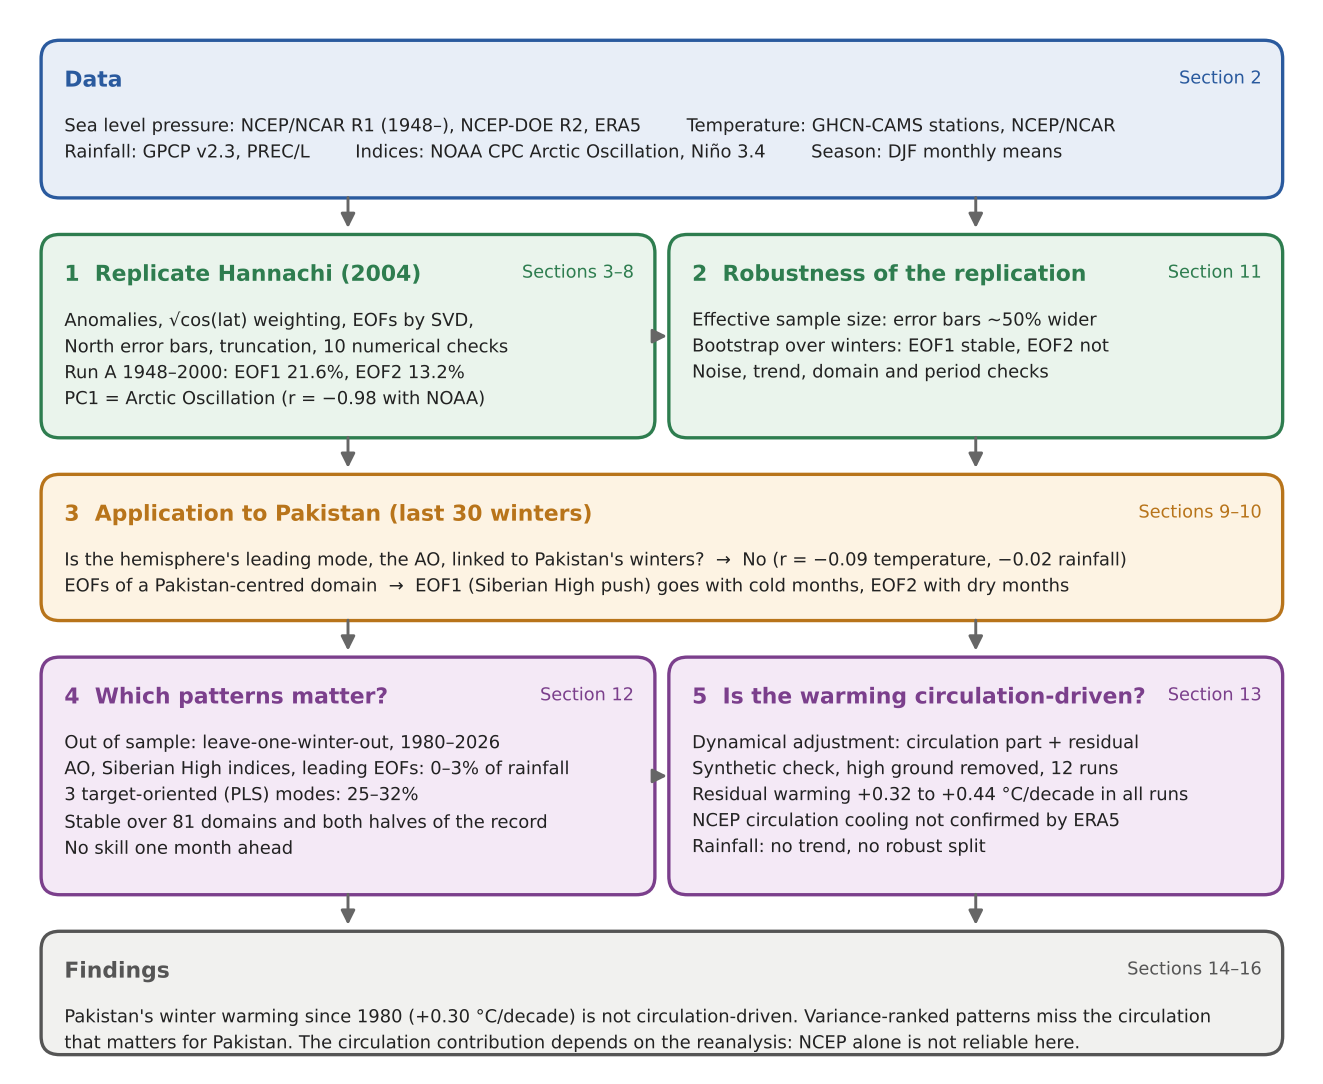

## 1. Setup

In [1]:
!pip install -q cartopy netCDF4 h5netcdf

In [2]:
from dataclasses import dataclass
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from cartopy.util import add_cyclic_point
from scipy import stats
from shapely.geometry import box

%matplotlib inline
pd.set_option("display.precision", 3)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "legend.frameon": False,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"

# Everything worth reviewing is collected here and exported in Section 14
REVIEW = Path("review")
(REVIEW / "figures").mkdir(parents=True, exist_ok=True)
(REVIEW / "tables").mkdir(exist_ok=True)
TABLES, NOTES = {}, []


def show(name: str) -> None:
    """Label the current figure "Figure N", save it to review/figures/ and display it.

    `name` starts with the two-digit figure number, e.g. "01_spectrum_run_a".
    """
    fig = plt.gcf()
    fig.text(0, 1, f"Figure {int(name[:2])}", ha="left", va="bottom", fontweight="bold", color=GREY)
    fig.savefig(REVIEW / "figures" / f"fig{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def keep(name: str, table: pd.DataFrame) -> pd.DataFrame:
    """Store a table for the review bundle and return it for display."""
    TABLES[name] = table
    return table

## 2. Data

All files are NOAA monthly means stored as `variable(time, lat, lon)`. Missing files are downloaded from NOAA into `data/`.

| Name | Dataset | Grid | From | Used for |
|---|---|---|---|---|
| `slp` | NCEP/NCAR Reanalysis 1 sea level pressure | 2.5° | 1948 | The field analysed everywhere |
| `air` | NCEP/NCAR Reanalysis 1 surface air temperature | 2.5° | 1948 | Temperature target in Section 9 |
| `precip` | GPCP v2.3 precipitation (satellite and gauge) | 2.5° | 1979 | Rainfall target |
| `air_land` | GHCN-CAMS land temperature (stations) | 0.5° | 1948 | Temperature target in Sections 12–13, independent of the reanalysis |
| `precip_land` | PREC/L land precipitation (gauges) | 0.5° | 1948 | Second rainfall dataset in Section 12 |
| AO index | NOAA CPC monthly Arctic Oscillation index | – | 1950 | Validation in Section 5 |

A winter is named by the year of its January, so December 1996 belongs to winter 1997.

In [3]:
import shutil
import urllib.request

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# name -> (file, variable, units)
DATASETS = {
    "slp": ("slp.mon.mean.nc", "slp", "hPa"),
    "air": ("air.mon.mean.nc", "air", "°C"),
    "precip": ("precip.mon.mean.nc", "precip", "mm/day"),
    "air_land": ("ghcncams.air.mon.mean.nc", "air", "°C"),
    "precip_land": ("precl.precip.mon.mean.0.5x0.5.nc", "precip", "mm/day"),
}

# local file name -> NOAA download URLs, tried in order
PSL = "https://downloads.psl.noaa.gov/Datasets/"
DATA_URLS = {
    "slp.mon.mean.nc": [PSL + "ncep.reanalysis/Monthlies/surface/slp.mon.mean.nc",
                        PSL + "ncep.reanalysis.derived/surface/slp.mon.mean.nc"],
    "air.mon.mean.nc": [PSL + "ncep.reanalysis/Monthlies/surface/air.mon.mean.nc",
                        PSL + "ncep.reanalysis.derived/surface/air.mon.mean.nc"],
    "precip.mon.mean.nc": [PSL + "gpcp/precip.mon.mean.nc"],
    "ghcncams.air.mon.mean.nc": [PSL + "ghcncams/air.mon.mean.nc"],
    "precl.precip.mon.mean.0.5x0.5.nc": [PSL + "precl/0.5deg/precip.mon.mean.0.5x0.5.nc"],
    "monthly.ao.index.b50.current.ascii": [
        "https://www.cpc.ncep.noaa.gov/products/precip/CWlink/daily_ao_index/monthly.ao.index.b50.current.ascii"],
    "mslp.mon.mean.nc": [PSL + "ncep.reanalysis2/Monthlies/surface/mslp.mon.mean.nc",
                         PSL + "ncep.reanalysis2.derived/surface/mslp.mon.mean.nc"],
    "nina34.anom.data": ["https://psl.noaa.gov/data/correlation/nina34.anom.data"],
}

# Regions as latitude and longitude ranges
NH_20N = dict(lat=(20, 90), lon=(0, 360))           # the paper's domain
PAKISTAN_SLP = dict(lat=(10, 50), lon=(40, 100))    # Pakistan-centred pressure domain
TARGET_BOX = dict(lat=(0, 55), lon=(30, 110))       # temperature and rainfall maps
NORTH_PAKISTAN = dict(lat=(31, 37), lon=(69, 77))


def find_file(file: str) -> Path | None:
    """The file in data/ or data/compact/, or None."""
    for path in (DATA_DIR / file, DATA_DIR / "compact" / file):
        if path.exists() and path.stat().st_size > 0:
            return path
    return None


def fetch(file: str, required: bool = True) -> Path | None:
    """Return the local copy of a file, downloading it from NOAA into data/ if needed."""
    path = find_file(file)
    if path is not None:
        return path
    target = DATA_DIR / file
    partial = target.with_name(target.name + ".part")
    errors = []
    for url in DATA_URLS.get(file, []):
        try:
            print(f"downloading {file} from {url} ...", flush=True)
            request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(request, timeout=300) as response, open(partial, "wb") as out:
                shutil.copyfileobj(response, out, 1 << 20)
            partial.rename(target)
            print(f"  saved {target} ({target.stat().st_size / 1e6:.0f} MB)")
            return target
        except Exception as error:
            partial.unlink(missing_ok=True)
            errors.append(f"{url}: {error}")
    if required:
        raise RuntimeError(f"could not find or download {file}:\n" + "\n".join(errors))
    return None


def open_field(name: str) -> xr.DataArray:
    """Open one dataset as (time, lat, lon) with latitude ascending, downloading it if missing."""
    file, var, units = DATASETS[name]
    path = fetch(file)
    ds = xr.open_dataset(path, drop_variables=["time_bnds", "lat_bnds", "lon_bnds", "climatology_bounds"])
    da = ds[var].sortby("lat")
    if da.attrs.get("units") in ("degK", "K", "deg K", "Kelvin", "kelvin"):
        da = da - 273.15
    if da.attrs.get("units") in ("Pa", "Pascals"):
        da = da / 100
    return da.assign_attrs(units=units)


def select_box(da: xr.DataArray, lat: tuple, lon: tuple) -> xr.DataArray:
    """Subset to a latitude / longitude box."""
    return da.sel(lat=slice(*lat), lon=slice(*lon))


def select_winters(da: xr.DataArray, start: str, end: str) -> xr.DataArray:
    """Keep the DJF months between two dates and label each with its winter."""
    da = da.sel(time=slice(start, end))
    da = da.sel(time=da.time.dt.month.isin([12, 1, 2])).load().astype("float64")
    winter = da.time.dt.year + (da.time.dt.month == 12)
    return da.assign_coords(winter=("time", winter.values))


def last_complete_winter(name: str) -> int:
    """Year of the last February in a dataset."""
    t = open_field(name).time
    return int(t.dt.year[t.dt.month == 2].max())


# Get every required file now, so a missing one fails here with a clear message
for name in DATASETS:
    fetch(DATASETS[name][0])
fetch("monthly.ao.index.b50.current.ascii")
print("all required data present")

downloading slp.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis/Monthlies/surface/slp.mon.mean.nc ...
downloading slp.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis.derived/surface/slp.mon.mean.nc ...
  saved data/slp.mon.mean.nc (22 MB)
downloading air.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis/Monthlies/surface/air.mon.mean.nc ...
downloading air.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis.derived/surface/air.mon.mean.nc ...
  saved data/air.mon.mean.nc (30 MB)
downloading precip.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/gpcp/precip.mon.mean.nc ...
  saved data/precip.mon.mean.nc (20 MB)
downloading ghcncams.air.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ghcncams/air.mon.mean.nc ...
  saved data/ghcncams.air.mon.mean.nc (187 MB)
downloading precl.precip.mon.mean.0.5x0.5.nc from https://downloads.psl.noaa.gov/Datasets/precl/0.5deg/precip.mon.mean.0

In [4]:
slp = open_field("slp")

# Run B must end at a winter that every dataset of Sections 5-12 covers, or the series would not line up
CORE = ["slp", "air", "precip", "air_land"]
ends = {name: last_complete_winter(name) for name in CORE}
last_winter = min(ends.values())                                    # last complete winter common to all
print("last complete winter in each dataset:", ends)

PAPER_PERIOD = ("1948-01", "2000-12")                                # Run A: the paper's sample
LAST_30 = (f"{last_winter - 30}-12", f"{last_winter}-02")            # Run B: last 30 complete winters

print(f"SLP: {slp.sizes['time']} months, {str(slp.time.values[0])[:7]} to {str(slp.time.values[-1])[:7]}, "
      f"grid {slp.sizes['lat']} x {slp.sizes['lon']}")
print("Run A:", PAPER_PERIOD, "| Run B:", LAST_30)

last complete winter in each dataset: {'slp': 2026, 'air': 2026, 'precip': 2026, 'air_land': 2026}
SLP: 938 months, 1948-01 to 2026-02, grid 73 x 144
Run A: ('1948-01', '2000-12') | Run B: ('1996-12', '2026-02')


Two further files are used in Section 12: NCEP-DOE Reanalysis 2 sea level pressure and the Niño 3.4 index.

In [5]:
DATASETS["slp_r2"] = ("mslp.mon.mean.nc", "mslp", "hPa")            # NCEP-DOE Reanalysis 2 pressure
DOWNLOAD_EXTRA = True

for file in ["mslp.mon.mean.nc", "nina34.anom.data"]:
    path = fetch(file, required=False) if DOWNLOAD_EXTRA else find_file(file)
    if path is None:
        NOTES.append(f"{file} not available")
    print(f"{file}: {'found' if path is not None else 'not found (optional)'}")


def load_nino34() -> pd.Series | None:
    """Monthly Niño 3.4 sea surface temperature anomaly (NOAA PSL text format), or None if absent."""
    path = find_file("nina34.anom.data")
    if path is None:
        return None
    rows = [line.split() for line in path.read_text().splitlines()]
    rows = [r for r in rows if len(r) == 13 and len(r[0]) == 4 and r[0].isdigit()]
    values = np.array([r[1:] for r in rows], dtype=float).ravel()
    index = pd.date_range(f"{rows[0][0]}-01-01", periods=len(values), freq="MS")
    return pd.Series(np.where(values < -90, np.nan, values), index=index, name="nino34")

downloading mslp.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis2/Monthlies/surface/mslp.mon.mean.nc ...
downloading mslp.mon.mean.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis2.derived/surface/mslp.mon.mean.nc ...
  saved data/mslp.mon.mean.nc (9 MB)
mslp.mon.mean.nc: found
downloading nina34.anom.data from https://psl.noaa.gov/data/correlation/nina34.anom.data ...
  saved data/nina34.anom.data (0 MB)
nina34.anom.data: found


## 3. Method (Hannachi 2004, Sections 2–3)

### 3.1 Anomalies, equations (3)–(4)

Subtract from every month the mean of that calendar month over the analysis window ("monthly averaged values then removed", §3.5):

$$X'(t, s) = X(t, s) - \bar{X}_{m(t)}(s).$$

In [6]:
def anomalies(da: xr.DataArray) -> xr.DataArray:
    """Eq. (3)-(4): remove the mean of each calendar month."""
    monthly = da.groupby("time.month")
    return (monthly - monthly.mean("time")).drop_vars("month").assign_attrs(da.attrs)

### 3.2 Area weighting, equations (5)–(6)

Grid points crowd together near the pole, so the data are weighted by latitude: $X'_w = X' D$.

The paper prints $D = \operatorname{diag}(\cos\phi)$. We use $D = \operatorname{diag}(\sqrt{\cos\phi})$ by default: the covariance is then weighted by $\cos\phi$, the area of a grid cell, and Section 6 shows this is what reproduces the paper's numbers.

In [7]:
def area_weights(anom: xr.DataArray, scheme: str = "sqrtcos") -> np.ndarray:
    """Eq. (5): the diagonal of D as a (lat, lon) map.

    "cos"      cos(lat), eq. (5) as printed
    "sqrtcos"  sqrt(cos(lat)), so the covariance is weighted by cell area (default)
    "none"     no weighting
    """
    cos = np.cos(np.deg2rad(anom.lat.values)).clip(min=0)
    cos[np.isclose(anom.lat.values, 90)] = 0                       # the pole has no area; cos(90°) is 6e-17 in floating point
    by_lat = {"cos": cos, "sqrtcos": np.sqrt(cos), "none": np.ones_like(cos)}[scheme]
    return np.repeat(by_lat[:, None], anom.lon.size, axis=1)

### 3.3 EOFs by singular value decomposition, equations (1)–(2), (7)–(10), (13)

The field (n times on a $p_1 \times p_2$ grid) is reshaped into the data matrix $X'_w$ with one row per month and $p = p_1 p_2$ columns. The EOFs $a_k$ are the eigenvectors of its covariance matrix and the principal components (PCs) are the projections of the data on them:

$$\Sigma = \frac{1}{n-1} X_w'^{T} X'_w, \qquad \Sigma\, a_k = \lambda_k a_k, \qquad c_k = X'_w a_k.$$

Because $p \gg n$, we never form $\Sigma$. The SVD $X'_w = U S V^T$ gives everything: the rows of $V^T$ are the EOFs, $\lambda_k = s_k^2/(n-1)$, and the PCs are the columns of $US$. EOF $k$ explains $100\,\lambda_k / \sum_j \lambda_j$ percent of the variance.

In [8]:
@dataclass
class EOFResult:
    """Output of one EOF analysis (K = number of non-zero eigenvalues)."""
    anom: xr.DataArray      # anomalies X' (time, lat, lon), physical units
    weights: np.ndarray     # diagonal of D as a (lat, lon) map
    eofs: np.ndarray        # (K, lat, lon) unit-length EOFs a_k
    pcs: np.ndarray         # (n, K) principal components c_k
    eigvals: np.ndarray     # (K,) eigenvalues of the covariance matrix

    @property
    def n(self) -> int:
        return self.pcs.shape[0]

    @property
    def time(self) -> pd.DatetimeIndex:
        return pd.DatetimeIndex(self.anom.time.values)

    @property
    def var_pct(self) -> np.ndarray:
        """Variance explained by each EOF, in percent (eq. 9)."""
        return 100 * self.eigvals / self.eigvals.sum()

    @property
    def pcs_std(self) -> np.ndarray:
        """PCs scaled to unit variance."""
        return self.pcs / self.pcs.std(axis=0, ddof=1)


def flip_sign(res: EOFResult, k: int) -> None:
    """EOFs are defined only up to sign (§3.4): flip EOF k and its PC."""
    res.eofs[k] *= -1
    res.pcs[:, k] *= -1


def compute_eofs(anom: xr.DataArray, weighting: str = "sqrtcos") -> EOFResult:
    """EOF analysis of an anomaly field by SVD."""
    n, p1, p2 = anom.shape
    weights = area_weights(anom, weighting)
    X = anom.values.reshape(n, p1 * p2)                   # eq. (2): data matrix, n x p
    Xw = X * weights.ravel()                              # eq. (6): X'_w = X' D
    U, s, Vt = np.linalg.svd(Xw, full_matrices=False)     # eq. (13)
    eigvals = s**2 / (n - 1)                              # eq. (7)-(9)
    keep = eigvals > 1e-12 * eigvals[0]                   # drop the numerically-zero tail
    res = EOFResult(anom, weights, Vt[keep].reshape(-1, p1, p2), (U * s)[:, keep], eigvals[keep])
    for k in range(len(res.eigvals)):                     # default sign: largest loading positive
        if res.eofs[k].flat[np.abs(res.eofs[k]).argmax()] < 0:
            flip_sign(res, k)
    return res


def regression_map(res: EOFResult, k: int) -> np.ndarray:
    """Anomalies regressed on standardised PC k: physical units per s.d. of the PC.

    This is the usual way to draw an EOF map.
    """
    return np.tensordot(res.pcs_std[:, k], res.anom.values, axes=1) / (res.n - 1)


def orient(res: EOFResult, k: int, region: np.ndarray, positive: bool = True) -> None:
    """Choose the sign of EOF k from its mean pressure anomaly over `region` (a lat-lon mask)."""
    coslat = np.cos(np.deg2rad(res.anom.lat.values))[:, None]
    if (np.sum(regression_map(res, k) * region * coslat) > 0) != positive:
        flip_sign(res, k)


def reconstruct(res: EOFResult, k: int) -> np.ndarray:
    """Eq. (11): anomalies rebuilt from the leading k EOFs, in physical units."""
    Xw_hat = np.tensordot(res.pcs[:, :k], res.eofs[:k], axes=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(res.weights > 0, Xw_hat / res.weights, np.nan)

### 3.4 Sampling error of the eigenvalues, equation (12)

The paper's equation (12), North's rule of thumb: the sampling error of an eigenvalue is about $\delta\lambda_k \approx \lambda_k \sqrt{2/n}$. If the error bars of two neighbouring eigenvalues overlap, their EOFs can mix and should not be read as separate patterns.

In [9]:
def north_error(var_pct: np.ndarray, n: float) -> np.ndarray:
    """Eq. (12): sampling error of each eigenvalue for n independent samples."""
    return var_pct * np.sqrt(2 / n)


def separated(var_pct: np.ndarray, err: np.ndarray) -> np.ndarray:
    """True where an eigenvalue's error bar overlaps neither neighbour's."""
    low, high = var_pct - err, var_pct + err
    ok = np.ones(len(var_pct), dtype=bool)
    ok[1:] &= high[1:] < low[:-1]
    ok[:-1] &= low[:-1] > high[1:]
    return ok


def eof_table(res: EOFResult, k: int = 10) -> pd.DataFrame:
    """Variance, cumulative variance, North error and separation of the leading k EOFs."""
    err = north_error(res.var_pct, res.n)
    return pd.DataFrame({
        "variance_%": res.var_pct[:k],
        "cumulative_%": np.cumsum(res.var_pct)[:k],
        "north_error_%": err[:k],
        "separated": separated(res.var_pct, err)[:k],
    }, index=pd.RangeIndex(1, k + 1, name="EOF"))

### 3.5 Plotting helpers

One function each for the paper's three figures: the eigenvalue spectrum, maps, and PC time series.

In [10]:
def country_outline(name: str = "Pakistan"):
    """Country polygon from Natural Earth."""
    shp = shpreader.natural_earth(resolution="50m", category="cultural", name="admin_0_countries")
    return next(r.geometry for r in shpreader.Reader(shp).records() if r.attributes["NAME"] == name)


PAKISTAN = country_outline("Pakistan")
_angle = np.linspace(0, 2 * np.pi, 100)
CIRCLE = mpath.Path(np.c_[np.sin(_angle), np.cos(_angle)] * 0.5 + 0.5)    # round frame for polar maps


def plot_spectrum(res: EOFResult, title: str, name: str, kmax: int = 50) -> None:
    """Fig. 1: eigenvalue spectrum with eq. (12) error bars."""
    err = north_error(res.var_pct, res.n)
    sep = separated(res.var_pct, err)[:kmax]
    rank, var, err = np.arange(1, kmax + 1), res.var_pct[:kmax], err[:kmax]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.errorbar(rank, var, yerr=err, fmt="none", ecolor=BLUE, capsize=2.5, lw=1)
    ax.scatter(rank[sep], var[sep], s=28, color=BLUE, zorder=3, label="separated from neighbours")
    ax.scatter(rank[~sep], var[~sep], s=28, facecolor="white", edgecolor=BLUE, zorder=3,
               label="overlaps a neighbour")
    ax.set(xlabel="Rank", ylabel="Eigenvalue (% of total variance)", title=title)
    ax.legend()
    show(name)


def plot_maps(maps, lat, lon, titles, label, name, polar=True, extent=(40, 100, 8, 48),
              cmap="RdBu_r", pvalues=None) -> None:
    """Fig. 2: filled-contour maps on a shared symmetric colour scale.

    polar=True draws the hemisphere north of 20N; otherwise the region `extent`
    with Pakistan outlined. Dots mark grid points with p < 0.05 when `pvalues` is given.
    """
    data = ccrs.PlateCarree()
    vmax = np.nanpercentile(np.abs(maps), 99)
    levels = np.linspace(-vmax, vmax, 13)
    height = 4.8 if polar else 4.6 * (extent[3] - extent[2]) / (extent[1] - extent[0]) + 1.4
    fig, axes = plt.subplots(1, len(maps), figsize=(4.6 * len(maps), height), squeeze=False,
                             subplot_kw={"projection": ccrs.NorthPolarStereo() if polar else data})
    for i, ax in enumerate(axes[0]):
        field, x = add_cyclic_point(maps[i], coord=lon) if polar else (maps[i], lon)
        filled = ax.contourf(x, lat, field, levels=levels, cmap=cmap, extend="both", transform=data)
        ax.coastlines(linewidth=0.5)
        ax.set_title(titles[i], loc="center")
        if polar:
            ax.set_extent([-180, 180, 20, 90], crs=data)
            ax.set_boundary(CIRCLE, transform=ax.transAxes)
        else:
            ax.set_extent(extent, crs=data)
            ax.add_geometries([PAKISTAN], data, facecolor="none", edgecolor="black", linewidth=1)
        if pvalues is not None:
            yy, xx = np.where(pvalues[i] < 0.05)
            ax.scatter(lon[xx], lat[yy], s=2, color="black", transform=data)
    fig.colorbar(filled, ax=axes, orientation="horizontal", shrink=0.6, pad=0.05, label=label,
                 ticks=levels[::3], format="%.2f")
    show(name)


def plot_eofs(res: EOFResult, name: str, ks=(0, 1), **kwargs) -> None:
    """EOF regression maps (hPa per s.d. of the PC) with their explained variance."""
    plot_maps([regression_map(res, k) for k in ks], res.anom.lat.values, res.anom.lon.values,
              [f"EOF{k + 1} ({res.var_pct[k]:.0f}% of variance)" for k in ks], "SLP anomaly (hPa per s.d. of the PC)",
              name, **kwargs)


def plot_pcs(res: EOFResult, name: str, ks=(0, 1)) -> None:
    """Fig. 3: standardised PCs, with the paper's +/-1 lines for high-amplitude months."""
    fig, axes = plt.subplots(len(ks), 1, figsize=(8, 2.4 * len(ks)), sharex=True)
    for ax, k, color in zip(axes, ks, [BLUE, ORANGE]):
        ax.plot(res.time, res.pcs_std[:, k], color=color, lw=0.8, marker=".", ms=3)
        ax.axhline(1, color=GREY, ls="--", lw=0.8)
        ax.axhline(-1, color=GREY, ls="--", lw=0.8)
        ax.set(ylim=(-3.6, 3.6), ylabel=f"PC{k + 1}")
    axes[0].set_title("Standardised principal components (DJF months)")
    axes[-1].set_xlabel("Year")
    show(name)

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


## 4. Replication: the paper's own sample (Run A, DJF 1948–2000)

The paper (§3.5) reports that EOF1 explains **21%** and EOF2 **13%** of the variance. EOF1 is the Arctic Oscillation (AO), drawn with high pressure over the pole.

In [11]:
nh = select_box(slp, **NH_20N)
polar_cap = (nh.lat.values >= 70)[:, None]

paper = compute_eofs(anomalies(select_winters(nh, *PAPER_PERIOD)))
orient(paper, 0, polar_cap, positive=True)             # the paper's sign: high over the pole

print(f"X': n = {paper.n} months x p = {paper.anom[0].size} grid points "
      f"({int((paper.weights > 0).sum())} with non-zero weight)")
print(f"largest |column mean| of X' = {np.abs(paper.anom.mean('time')).max().item():.1e} hPa (centred, eq. 4)")
print(f"EOF1: paper 21%, here {paper.var_pct[0]:.1f}%   EOF2: paper 13%, here {paper.var_pct[1]:.1f}%")
keep("eof_table_run_a", eof_table(paper))

X': n = 159 months x p = 4176 grid points (4032 with non-zero weight)
largest |column mean| of X' = 8.7e-14 hPa (centred, eq. 4)
EOF1: paper 21%, here 21.6%   EOF2: paper 13%, here 13.2%


,variance_%,cumulative_%,north_error_%,separated
EOF,,,,
1,21.622,21.622,2.425,True
2,13.246,34.867,1.486,True
3,9.686,44.553,1.086,False
4,7.787,52.339,0.873,False
5,7.394,59.734,0.829,False
6,6.998,66.731,0.785,False
7,4.911,71.642,0.551,False
8,4.142,75.784,0.465,False
9,3.534,79.317,0.396,False


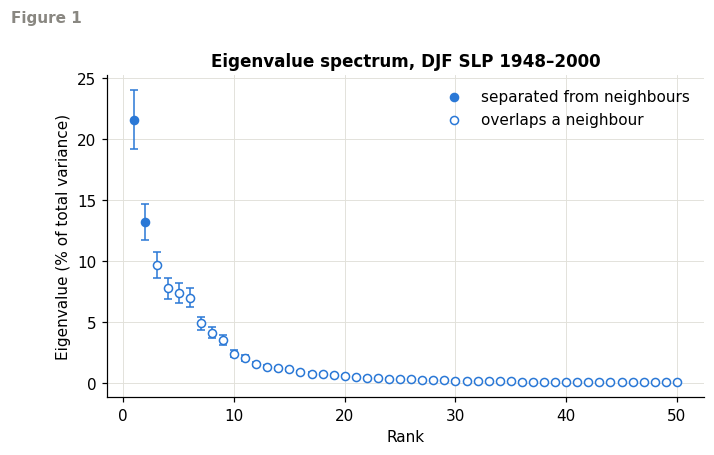

In [12]:
plot_spectrum(paper, "Eigenvalue spectrum, DJF SLP 1948–2000", "01_spectrum_run_a")

**Figure 1. Eigenvalue spectrum of Run A (the paper's Fig. 1).** Share of variance explained by each EOF, with eq. (12) error bars. Filled points are separated from both neighbours. EOF1 and EOF2 stand clear. Further down the bars overlap, as the paper notes: "the spectrum looks in general continuous".

/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


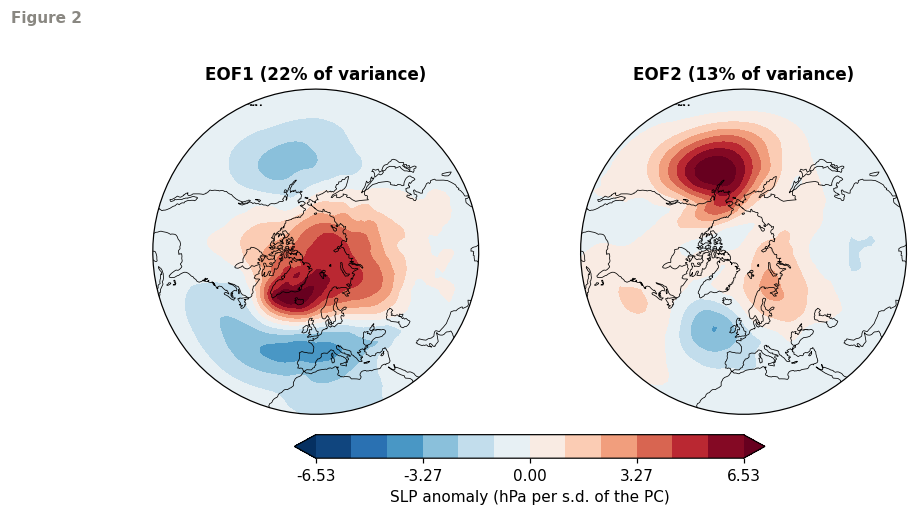

In [13]:
plot_eofs(paper, "02_eofs_run_a")

**Figure 2. The two leading EOFs of Run A (the paper's Fig. 2).** Pressure anomaly that goes with one standard deviation of each PC. EOF1 is the **Arctic Oscillation**: one centre over the Arctic and opposite centres over the North Atlantic–Mediterranean and the North Pacific. EOF2 has separate North Pacific and North East Atlantic centres. Both match the paper.

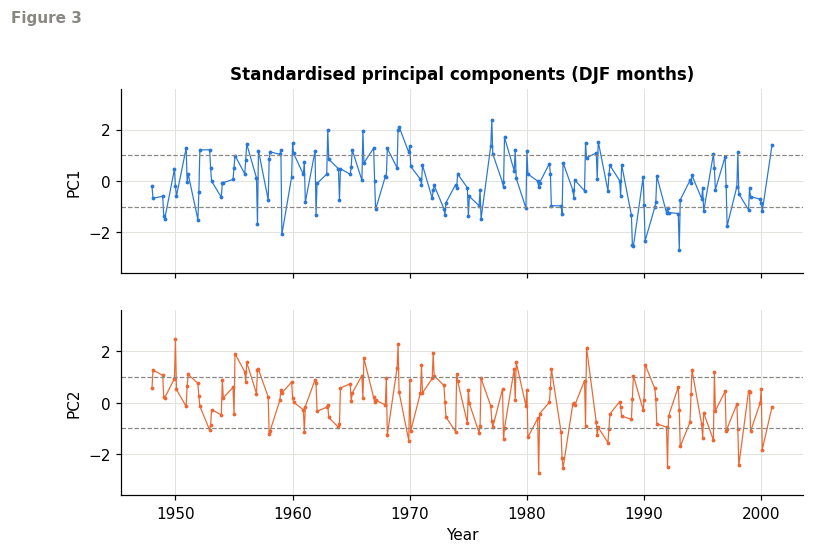

In [14]:
plot_pcs(paper, "03_pcs_run_a")

**Figure 3. The two leading PCs of Run A (the paper's Fig. 3).** One value per winter month. Dashed lines at ±1 mark the paper's high-amplitude months.

## 5. Replication: the last 30 winters (Run B)

The same analysis on the 90 DJF months of the last 30 complete winters, the window used for the application.

In [15]:
recent = compute_eofs(anomalies(select_winters(nh, *LAST_30)))
orient(recent, 0, polar_cap, positive=True)

print(f"{recent.time[0]:%b %Y} to {recent.time[-1]:%b %Y}: n = {recent.n} months")
keep("eof_table_run_b", eof_table(recent))

Dec 1996 to Feb 2026: n = 90 months


,variance_%,cumulative_%,north_error_%,separated
EOF,,,,
1,24.110,24.110,3.594,True
2,13.657,37.767,2.036,True
3,9.589,47.356,1.430,False
4,7.750,55.107,1.155,False
5,7.476,62.583,1.115,False
6,6.210,68.794,0.926,False
7,4.797,73.591,0.715,False
8,3.457,77.047,0.515,False
9,3.128,80.175,0.466,False


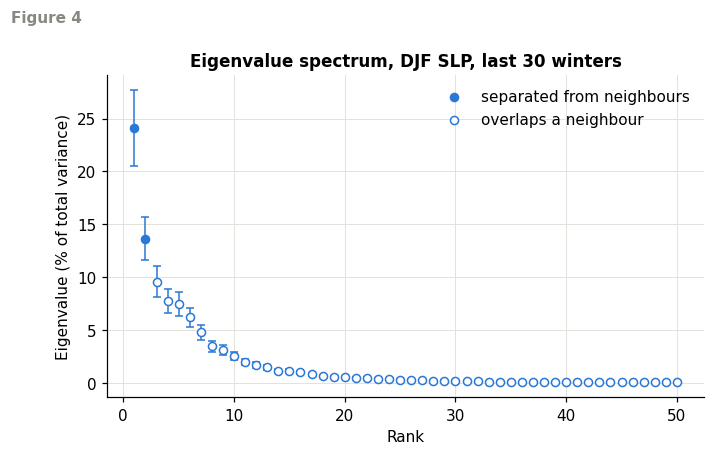

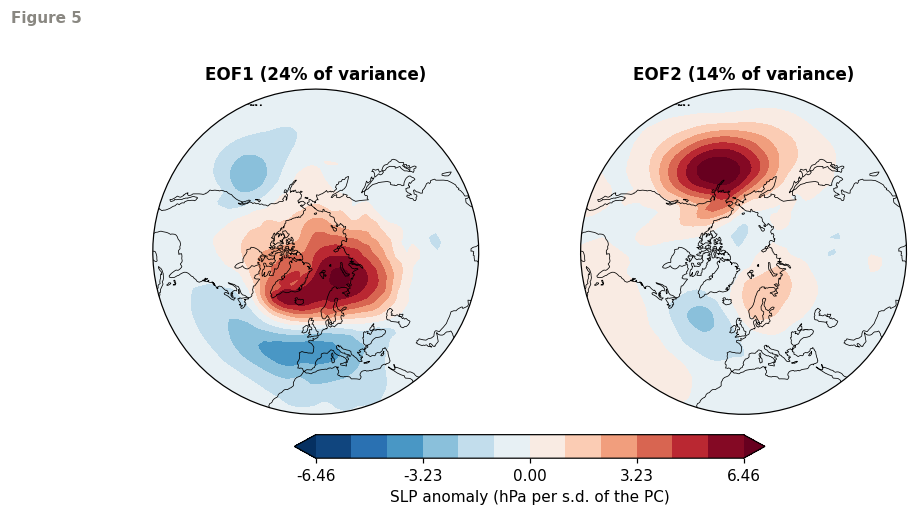

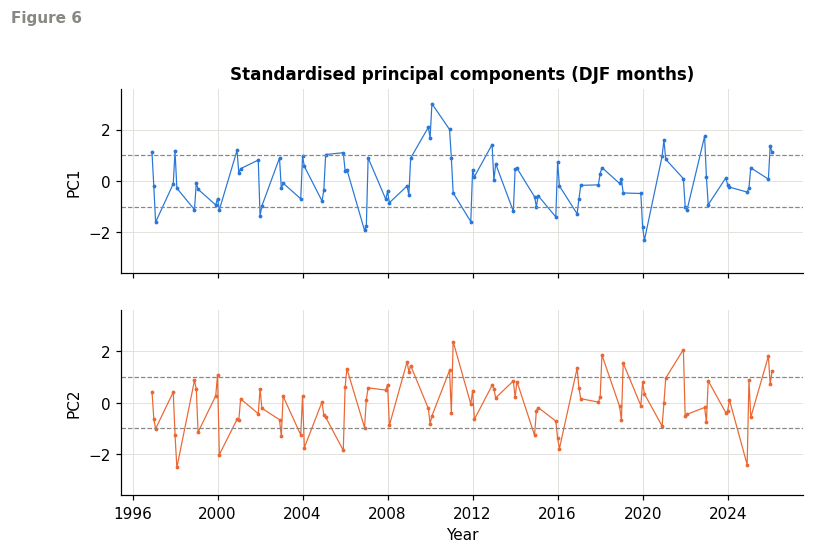

In [16]:
plot_spectrum(recent, "Eigenvalue spectrum, DJF SLP, last 30 winters", "04_spectrum_run_b")
plot_eofs(recent, "05_eofs_run_b")
plot_pcs(recent, "06_pcs_run_b")

**Figures 4–6. The same three figures for Run B.** The spectrum, the two leading EOFs and their PCs for the last 30 winters. The modes are the same as in Run A. The error bars are wider because there are fewer months.

### Validation against NOAA's AO index

NOAA CPC's official AO index is built from 1000 hPa heights. A correlation near ±1 confirms that our PC1 is the AO. The sign is negative only because the paper draws high pressure over the pole and NOAA does the opposite.

In [17]:
def load_cpc_ao() -> pd.Series:
    """NOAA CPC monthly AO index."""
    df = pd.read_csv(fetch("monthly.ao.index.b50.current.ascii"),
                     sep=r"\s+", names=["year", "month", "ao"])
    return pd.Series(df["ao"].values, index=pd.to_datetime(df[["year", "month"]].assign(day=1)))


cpc_ao = load_cpc_ao()
cpc_corr = {}
for name, res in [("Run A", paper), ("Run B", recent)]:
    both = pd.concat([pd.Series(res.pcs_std[:, 0], res.time), cpc_ao], axis=1, join="inner")
    cpc_corr[name] = both.corr().iloc[0, 1]
    print(f"{name}: corr(PC1, CPC AO) = {cpc_corr[name]:+.3f} over {len(both)} months")
keep("cpc_ao_correlation", pd.Series(cpc_corr, name="corr(PC1, CPC AO)").to_frame())

Run A: corr(PC1, CPC AO) = -0.984 over 153 months
Run B: corr(PC1, CPC AO) = -0.964 over 90 months


,"corr(PC1, CPC AO)"
Run A,-0.984
Run B,-0.964


## 6. Which weighting did the paper use?

In [18]:
rows = {}
for scheme in ["cos", "sqrtcos", "none"]:
    a = compute_eofs(anomalies(select_winters(nh, *PAPER_PERIOD)), scheme)
    b = compute_eofs(anomalies(select_winters(nh, *LAST_30)), scheme)
    rows[scheme] = [a.var_pct[0], a.var_pct[1], b.var_pct[0], b.var_pct[1]]
rows["paper"] = [21, 13, np.nan, np.nan]
keep("weighting_comparison", pd.DataFrame(rows, index=["Run A EOF1 %", "Run A EOF2 %", "Run B EOF1 %", "Run B EOF2 %"]).T.round(1))

,Run A EOF1 %,Run A EOF2 %,Run B EOF1 %,Run B EOF2 %
cos,18.8,14.9,20.4,16.1
sqrtcos,21.6,13.2,24.1,13.7
none,35.9,10.1,36.9,11.6
paper,21.0,13.0,NaN,NaN


Only $\sqrt{\cos\phi}$ reproduces the paper's 21% and 13%. Without weighting, EOF1 is inflated to about 36%, because the many small polar cells are over-counted: the artefact §2.2 warns about.

## 7. Truncation and reconstruction, equation (11)

Keeping the leading $k$ EOFs gives the best rank-$k$ approximation of the data: $X' \approx \sum_{j=1}^{k} c_j a_j^T$.

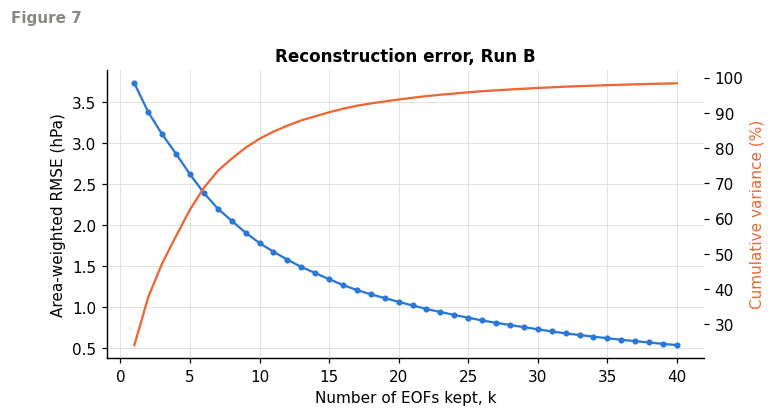

k =  1:  24.1% of variance, RMSE 3.73 hPa
k =  5:  62.6% of variance, RMSE 2.62 hPa
k = 10:  82.7% of variance, RMSE 1.78 hPa
k = 20:  93.8% of variance, RMSE 1.06 hPa


In [19]:
ks = np.arange(1, 41)
discarded = recent.eigvals.sum() - np.cumsum(recent.eigvals)       # variance left out by k EOFs
rmse = np.sqrt((recent.n - 1) * discarded / (recent.n * (recent.weights**2).sum()))[:40]
cumulative = np.cumsum(recent.var_pct)[:40]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(ks, rmse, color=BLUE, marker="o", ms=3)
ax.set(xlabel="Number of EOFs kept, k", ylabel="Area-weighted RMSE (hPa)", title="Reconstruction error, Run B")
ax2 = ax.twinx()
ax2.plot(ks, cumulative, color=ORANGE)
ax2.set_ylabel("Cumulative variance (%)", color=ORANGE)
ax2.grid(False)
show("07_reconstruction_error")

for k in (1, 5, 10, 20):
    print(f"k = {k:2d}: {cumulative[k - 1]:5.1f}% of variance, RMSE {rmse[k - 1]:.2f} hPa")

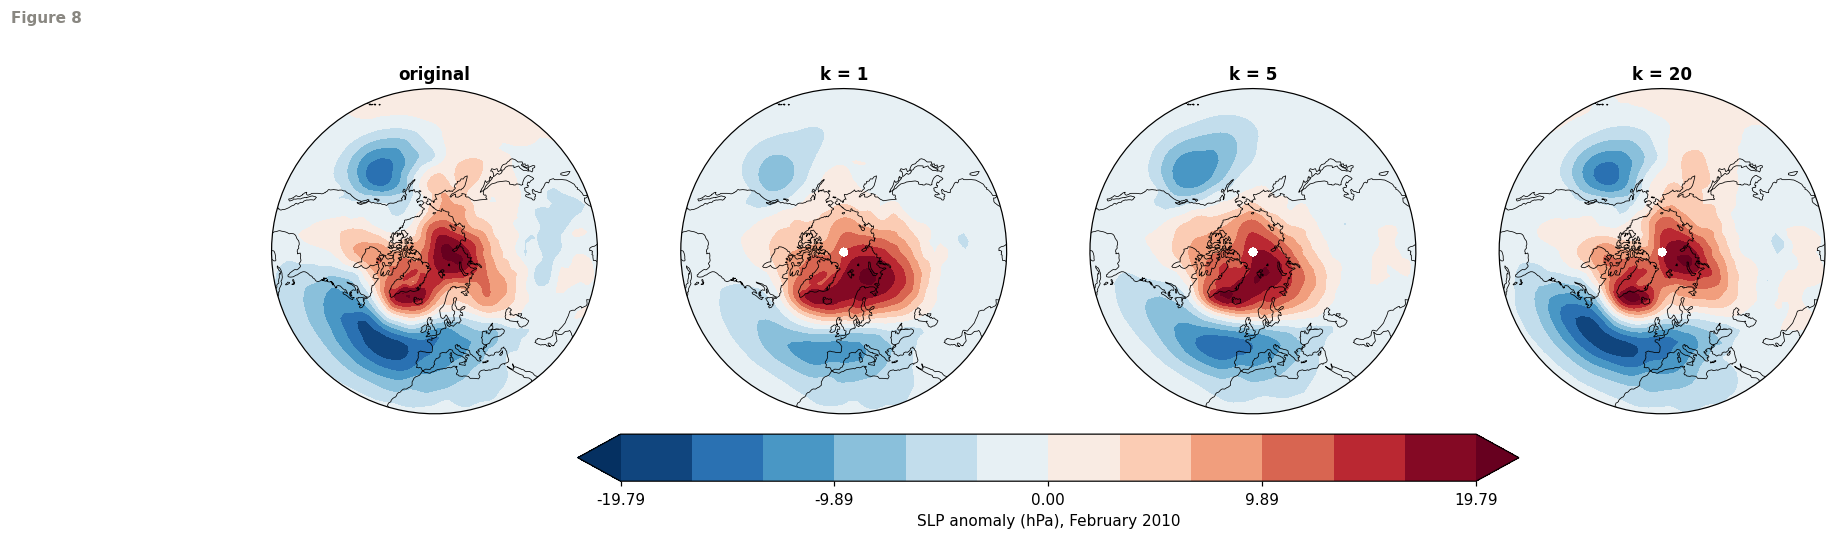

In [20]:
t = np.abs(recent.pcs_std[:, 0]).argmax()                          # the month with the strongest AO
plot_maps([recent.anom.values[t]] + [reconstruct(recent, k)[t] for k in (1, 5, 20)],
          recent.anom.lat.values, recent.anom.lon.values,
          ["original", "k = 1", "k = 5", "k = 20"], f"SLP anomaly (hPa), {recent.time[t]:%B %Y}",
          "08_reconstruction_maps")

**Figure 7. Reconstruction error against the number of EOFs kept (Run B).** Blue: area-weighted error of the rebuilt field. Orange: cumulative variance explained.

**Figure 8. One month rebuilt from 1, 5 and 20 EOFs.** The month with the strongest AO. One EOF gives the polar centre, five give the main features, twenty are close to the original.

## 8. Numerical checks

Each check tests a property derived in Section 3 of the paper, on Run B.

In [21]:
n, K = recent.n, len(recent.eigvals)
Xw = (recent.anom.values * recent.weights).reshape(n, -1)
A = recent.eofs.reshape(K, -1)                                     # EOFs as rows
C = recent.pcs
eig_direct = np.sort(np.linalg.eigvalsh(Xw @ Xw.T / (n - 1)))[::-1][:20]
rank5_error = np.sum((Xw - C[:, :5] @ A[:5]) ** 2)

checks = {
    "anomalies are centred (eq. 4)": np.abs(recent.anom.mean("time")).max().item() < 1e-8,
    "EOFs are orthonormal": np.allclose(A[:20] @ A[:20].T, np.eye(20), atol=1e-10),
    "PCs are uncorrelated": np.allclose(np.corrcoef(C[:, :20].T), np.eye(20), atol=1e-8),
    "SVD eigenvalues = eigenvalues of Sigma (eq. 9, 13)": np.allclose(eig_direct, recent.eigvals[:20]),
    "Sigma a_1 = lambda_1 a_1 (eq. 9)": np.allclose(Xw.T @ (Xw @ A[0]) / (n - 1), recent.eigvals[0] * A[0]),
    "PC_1 = X'_w a_1 (eq. 10)": np.allclose(Xw @ A[0], C[:, 0]),
    "full expansion rebuilds X' exactly (eq. 11)": np.nanmax(np.abs(reconstruct(recent, K) - recent.anom.values)) < 1e-8,
    "explained variances sum to 100%": np.isclose(recent.var_pct.sum(), 100),
    "rank-5 error = discarded singular values (Eckart-Young)": np.isclose(rank5_error, (n - 1) * recent.eigvals[5:].sum()),
    "paper's 21% / 13% reproduced": abs(paper.var_pct[0] - 21) < 1 and abs(paper.var_pct[1] - 13) < 1,
}
print(f"{sum(checks.values())} of {len(checks)} checks passed")
keep("numerical_checks", pd.Series(checks, name="passed").to_frame())

10 of 10 checks passed


,passed
anomalies are centred (eq. 4),True
EOFs are orthonormal,True
PCs are uncorrelated,True
"SVD eigenvalues = eigenvalues of Sigma (eq. 9, 13)",True
Sigma a_1 = lambda_1 a_1 (eq. 9),True
PC_1 = X'_w a_1 (eq. 10),True
full expansion rebuilds X' exactly (eq. 11),True
explained variances sum to 100%,True
rank-5 error = discarded singular values (Eckart-Young),True
paper's 21% / 13% reproduced,True


## 9. Application: Pakistan's winters

The paper's application stops at the hemispheric EOFs. Ours asks a different question with the same tools: **which pressure patterns shape winter temperature and rainfall in Pakistan?**

- **Part A.** Use PC1 of the hemispheric analysis (the AO) as a climate index.
- **Part B.** Repeat the EOF analysis on a Pakistan-centred domain, because EOFs depend on the domain (§3.4).

Both parts use the last 30 winters.

### 9.1 Targets and statistics

| Choice | What we use | Why |
|---|---|---|
| **Temperature target** | NCEP/NCAR surface air temperature, mean over Pakistan | Same source and grid as the pressure field |
| **Rainfall target** | GPCP precipitation, mean over Pakistan | Combines satellites and gauges, so it covers the northern mountains |
| **Area mean** | Each grid cell weighted by the fraction inside Pakistan | A 2.5° cell is larger than much of the country. Whole cells would bring in India and Afghanistan |
| **Second region** | Northern Pakistan, 31–37°N, 69–77°E | Where most winter rain and snow falls |
| **Significance** | t-test with the lag-1 effective sample size (see Method sources) | Consecutive months are correlated, so 90 months are fewer than 90 independent samples |

In [22]:
def country_fraction(lat: np.ndarray, lon: np.ndarray, country=PAKISTAN) -> np.ndarray:
    """Fraction of each grid cell that lies inside the country."""
    dlat, dlon = abs(lat[1] - lat[0]), abs(lon[1] - lon[0])
    frac = np.zeros((len(lat), len(lon)))
    for i, la in enumerate(lat):
        for j, lo in enumerate(lon):
            cell = box(lo - dlon / 2, la - dlat / 2, lo + dlon / 2, la + dlat / 2)
            frac[i, j] = country.intersection(cell).area / cell.area
    return frac


def box_fraction(lat: np.ndarray, lon: np.ndarray, region: dict) -> np.ndarray:
    """1 for grid points inside a latitude / longitude box, else 0."""
    in_lat = (lat >= region["lat"][0]) & (lat <= region["lat"][1])
    in_lon = (lon >= region["lon"][0]) & (lon <= region["lon"][1])
    return (in_lat[:, None] & in_lon[None, :]).astype(float)


def region_mean(field: xr.DataArray, frac: np.ndarray) -> pd.Series:
    """Area-weighted mean over a region (weight = cell fraction x cos(lat))."""
    w = frac * np.cos(np.deg2rad(field.lat.values))[:, None]
    return field.weighted(xr.DataArray(w, coords=[field.lat, field.lon])).mean(("lat", "lon")).to_series()


def lag1(x, axis: int = 0) -> np.ndarray:
    """Lag-1 autocorrelation along `axis`."""
    x = np.moveaxis(np.asarray(x, dtype=float), axis, 0)
    x = x - np.nanmean(x, axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.clip(np.nansum(x[:-1] * x[1:], axis=0) / np.nansum(x * x, axis=0), -0.99, 0.99)


def correlation_test(x, y) -> dict:
    """Pearson r, its p-value with n_eff = n (1 - r1x r1y) / (1 + r1x r1y), and the slope of y on x."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    r = np.corrcoef(x, y)[0, 1]
    a = lag1(x) * lag1(y)
    n_eff = np.clip(len(x) * (1 - a) / (1 + a), 3, len(x))
    t = r * np.sqrt((n_eff - 2) / (1 - r * r))
    return dict(r=r, p=2 * stats.t.sf(abs(t), n_eff - 2), slope=np.polyfit(x, y, 1)[0])


def correlation_map(index: pd.Series, field: xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
    """Correlation of every grid point with an index, and the p-value map."""
    x, Y = index.values, field.values
    n = len(x)
    xs = (x - x.mean()) / x.std(ddof=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        r = np.nansum(xs[:, None, None] * (Y - np.nanmean(Y, axis=0)), axis=0) / ((n - 1) * np.nanstd(Y, axis=0, ddof=1))
        a = lag1(x) * lag1(Y)
        n_eff = np.clip(n * (1 - a) / (1 + a), 3, n)
        t = r * np.sqrt((n_eff - 2) / np.clip(1 - r * r, 1e-12, None))
    return r, 2 * stats.t.sf(np.abs(t), n_eff - 2)


def composite_difference(index: pd.Series, field: xr.DataArray, threshold: float = 1.0):
    """Mean field when index > +threshold minus the mean when index < -threshold.

    The +/-1 threshold is the paper's definition of high-amplitude months (§3.5).
    Returns the difference, its Welch t-test p-value, and the two sample sizes.
    """
    high, low = field.values[index.values > threshold], field.values[index.values < -threshold]
    with np.errstate(invalid="ignore"):
        p = stats.ttest_ind(high, low, axis=0, equal_var=False, nan_policy="omit").pvalue
    return np.nanmean(high, axis=0) - np.nanmean(low, axis=0), np.asarray(p), len(high), len(low)


def detrend(s: pd.Series) -> pd.Series:
    """Remove a least-squares linear trend in time."""
    t = (s.index.year + (s.index.month - 0.5) / 12).values
    return s - np.polyval(np.polyfit(t, s.values, 1), t)


def link_table(index: pd.Series, winter: np.ndarray, targets: dict, detrended: bool = False) -> pd.DataFrame:
    """Correlation of an index with each target: same month, winter mean, and index leading by a month."""
    x = detrend(index) if detrended else index
    same_winter = winter[1:] == winter[:-1]
    rows = {}
    for name, y in targets.items():
        y = detrend(y) if detrended else y
        month = correlation_test(x, y)
        season = correlation_test(x.groupby(winter).mean(), y.groupby(winter).mean())
        lead = correlation_test(x.values[:-1][same_winter], y.values[1:][same_winter])
        rows[name] = dict(r_monthly=month["r"], p_monthly=month["p"], slope_per_sd=month["slope"],
                          r_winter_mean=season["r"], p_winter_mean=season["p"],
                          r_lead_1month=lead["r"], p_lead_1month=lead["p"])
    return pd.DataFrame(rows).T

In [23]:
air = anomalies(select_winters(select_box(open_field("air"), **TARGET_BOX), *LAST_30))
rain = anomalies(select_winters(select_box(open_field("precip"), **TARGET_BOX), *LAST_30))

targets = {
    "Pakistan T": region_mean(air, country_fraction(air.lat.values, air.lon.values)),
    "Pakistan P": region_mean(rain, country_fraction(rain.lat.values, rain.lon.values)),
    "N. Pakistan T": region_mean(air, box_fraction(air.lat.values, air.lon.values, NORTH_PAKISTAN)),
    "N. Pakistan P": region_mean(rain, box_fraction(rain.lat.values, rain.lon.values, NORTH_PAKISTAN)),
}
winter = air.winter.values

### 9.2 Part A: the Arctic Oscillation and Pakistan

The AO index is the standardised PC1 of Run B, with NOAA's sign (positive = low pressure over the Arctic).

In [24]:
orient(recent, 0, polar_cap, positive=False)                       # NOAA's sign
ao = pd.Series(recent.pcs_std[:, 0], recent.time, name="AO")

print("AO against Pakistan's winter anomalies")
display(keep("ao_vs_pakistan", link_table(ao, winter, targets)))
print("The same after removing linear trends")
display(keep("ao_vs_pakistan_detrended", link_table(ao, winter, targets, detrended=True)))

AO against Pakistan's winter anomalies


,r_monthly,p_monthly,slope_per_sd,r_winter_mean,p_winter_mean,r_lead_1month,p_lead_1month
Pakistan T,-0.091,0.411,-0.139,-0.207,0.271,-0.091,0.496
Pakistan P,-0.018,0.864,-0.010,0.127,0.512,0.191,0.144
N. Pakistan T,-0.080,0.487,-0.119,-0.212,0.261,-0.119,0.379
N. Pakistan P,-0.025,0.818,-0.021,0.110,0.572,0.177,0.176


The same after removing linear trends


,r_monthly,p_monthly,slope_per_sd,r_winter_mean,p_winter_mean,r_lead_1month,p_lead_1month
Pakistan T,-0.087,0.429,-0.128,-0.205,0.280,-0.087,0.512
Pakistan P,-0.021,0.848,-0.011,0.123,0.525,0.190,0.146
N. Pakistan T,-0.075,0.510,-0.108,-0.210,0.266,-0.116,0.386
N. Pakistan P,-0.026,0.805,-0.022,0.107,0.584,0.176,0.178


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


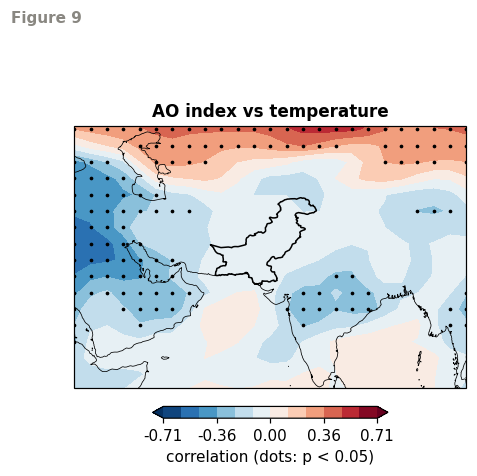

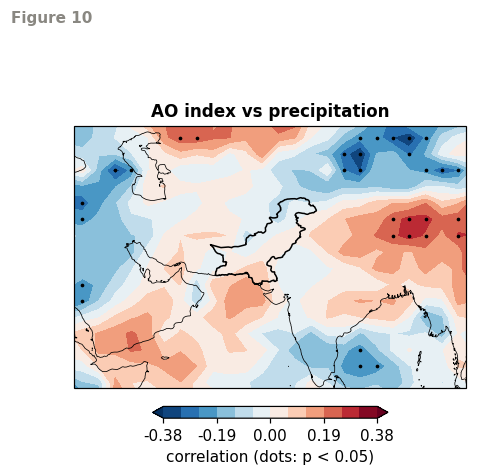

In [25]:
r_air, p_air = correlation_map(ao, air)
r_rain, p_rain = correlation_map(ao, rain)
plot_maps([r_air], air.lat.values, air.lon.values, ["AO index vs temperature"],
          "correlation (dots: p < 0.05)", "09_ao_correlation_temperature", polar=False, pvalues=[p_air])
plot_maps([r_rain], rain.lat.values, rain.lon.values, ["AO index vs precipitation"],
          "correlation (dots: p < 0.05)", "10_ao_correlation_precipitation", polar=False, pvalues=[p_rain])

**Figures 9–10. Correlation of the AO index with temperature and with precipitation at every grid point.** Pakistan is outlined. Dots mark significant grid points. Almost none fall inside Pakistan.

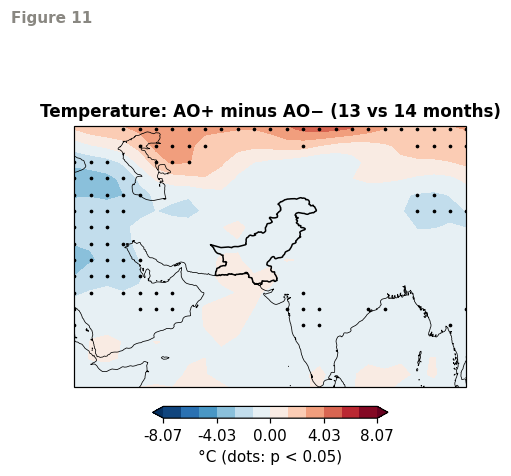

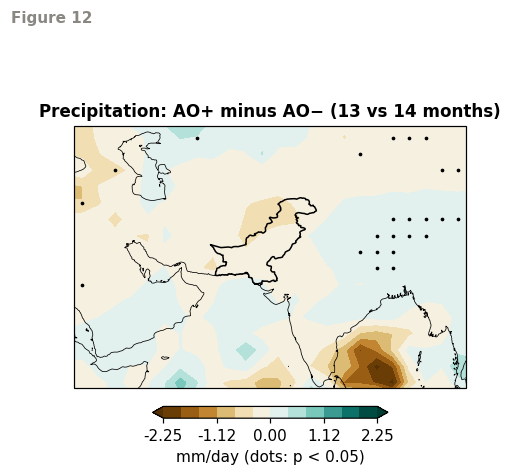

In [26]:
diff_air, pd_air, n_high, n_low = composite_difference(ao, air)
diff_rain, pd_rain, _, _ = composite_difference(ao, rain)
plot_maps([diff_air], air.lat.values, air.lon.values, [f"Temperature: AO+ minus AO− ({n_high} vs {n_low} months)"],
          "°C (dots: p < 0.05)", "11_ao_composite_temperature", polar=False, pvalues=[pd_air])
plot_maps([diff_rain], rain.lat.values, rain.lon.values, [f"Precipitation: AO+ minus AO− ({n_high} vs {n_low} months)"],
          "mm/day (dots: p < 0.05)", "12_ao_composite_precipitation", polar=False, pvalues=[pd_rain], cmap="BrBG")

**Figures 11–12. Composite difference: months with AO above +1 minus months with AO below −1.** The paper's ±1 threshold for high-amplitude months, used here to compare the two phases. Over Pakistan the differences are small and not significant.

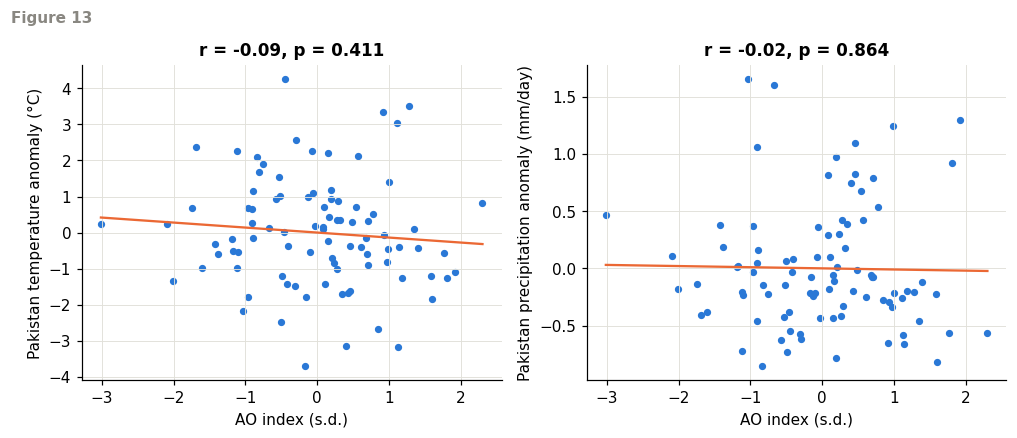

In [27]:
def plot_scatter(panels, name: str) -> None:
    """Scatter plots with a least-squares line; panels = [(x, y, xlabel, ylabel), ...]."""
    fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 3.8))
    for ax, (x, y, xlabel, ylabel) in zip(axes, panels):
        st = correlation_test(x, y)
        ax.scatter(x, y, s=14, color=BLUE)
        ax.plot(np.sort(x), np.polyval(np.polyfit(x, y, 1), np.sort(x)), color=ORANGE)
        ax.set(xlabel=xlabel, ylabel=ylabel, title=f"r = {st['r']:+.2f}, p = {st['p']:.3f}")
    fig.tight_layout()
    show(name)


plot_scatter([(ao.values, targets["Pakistan T"].values, "AO index (s.d.)", "Pakistan temperature anomaly (°C)"),
              (ao.values, targets["Pakistan P"].values, "AO index (s.d.)", "Pakistan precipitation anomaly (mm/day)")],
             "13_ao_scatter")

**Figure 13. Pakistan's monthly anomalies against the AO index.** Each point is one winter month. The fitted lines are flat.

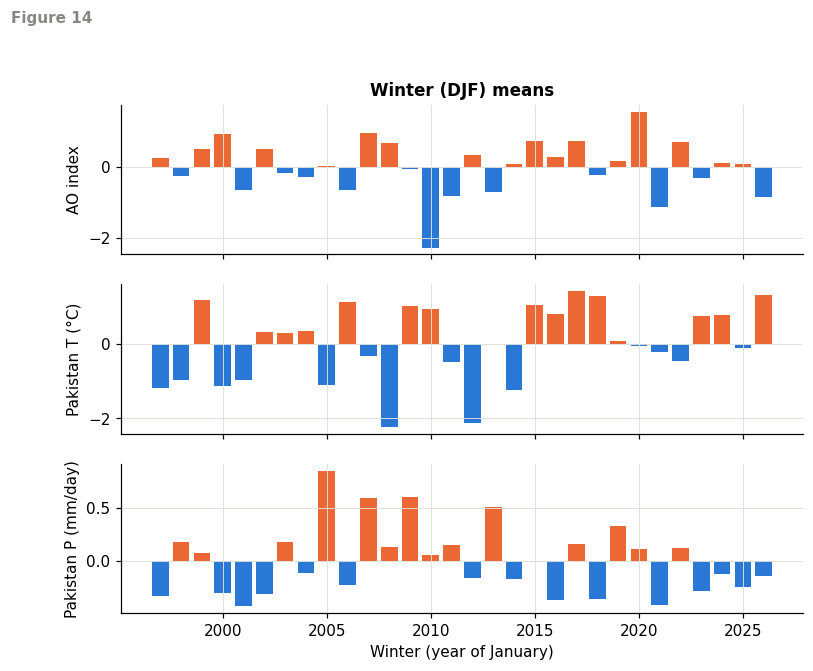

27 months with |AO| > 1; mean anomaly by phase:


,Pakistan T (°C),Pakistan P (mm/day)
AO+,-0.290,-0.187
AO−,-0.132,0.040


In [28]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
for ax, series, label in zip(axes, [ao, targets["Pakistan T"], targets["Pakistan P"]],
                             ["AO index", "Pakistan T (°C)", "Pakistan P (mm/day)"]):
    means = series.groupby(winter).mean()
    ax.bar(means.index, means.values, color=np.where(means > 0, ORANGE, BLUE))
    ax.set_ylabel(label)
axes[0].set_title("Winter (DJF) means")
axes[-1].set_xlabel("Winter (year of January)")
show("14_winter_means")

extreme = pd.DataFrame({"AO": ao, "Pakistan T (°C)": targets["Pakistan T"], "Pakistan P (mm/day)": targets["Pakistan P"]})
extreme = extreme[extreme["AO"].abs() > 1]
print(f"{len(extreme)} months with |AO| > 1; mean anomaly by phase:")
keep("ao_extreme_months_by_phase", extreme.groupby(np.where(extreme["AO"] > 0, "AO+", "AO−")).mean().iloc[:, 1:])

**Figure 14. Winter means of the AO index and of Pakistan's temperature and precipitation.** One bar per winter. The three series do not move together.

**Result.** The AO does not explain Pakistan's winters: its monthly correlation with temperature is about −0.09 and with rainfall about −0.02, neither significant, with or without trends. The hemisphere's leading mode is not the pattern that matters here.

### 9.3 Part B: Pakistan-centred EOFs

The same EOF analysis on SLP over 10–50°N, 40–100°E. Each mode is signed so that a positive PC means higher pressure averaged over the domain.

In [29]:
local = compute_eofs(anomalies(select_winters(select_box(slp, **PAKISTAN_SLP), *LAST_30)))
for k in range(5):
    orient(local, k, np.ones_like(local.weights))

keep("eof_table_pakistan_domain", eof_table(local, 6))

,variance_%,cumulative_%,north_error_%,separated
EOF,,,,
1,41.337,41.337,6.162,True
2,21.591,62.929,3.219,True
3,11.727,74.656,1.748,True
4,6.460,81.116,0.963,True
5,4.738,85.854,0.706,True
6,2.936,88.790,0.438,True


In [30]:
def mode_table(res: EOFResult, targets: dict, kmax: int = 5, detrended: bool = False) -> pd.DataFrame:
    """Correlation (r) and p-value of each leading PC with each target."""
    rows = {}
    for k in range(kmax):
        pc = pd.Series(res.pcs_std[:, k], res.time)
        row = {"variance_%": res.var_pct[k]}
        for name, y in targets.items():
            st = correlation_test(detrend(pc) if detrended else pc, detrend(y) if detrended else y)
            row[f"r {name}"], row[f"p {name}"] = st["r"], st["p"]
        rows[f"PC{k + 1}"] = row
    return pd.DataFrame(rows).T


display(keep("local_modes_vs_pakistan", mode_table(local, targets)))
print("The same after removing linear trends")
display(keep("local_modes_vs_pakistan_detrended", mode_table(local, targets, detrended=True)))

,variance_%,r Pakistan T,p Pakistan T,r Pakistan P,p Pakistan P,r N. Pakistan T,p N. Pakistan T,r N. Pakistan P,p N. Pakistan P
PC1,41.337,-0.405,1.154e-04,-0.056,6.014e-01,-0.284,0.010,-0.052,6.235e-01
PC2,21.591,-0.011,9.219e-01,-0.377,2.480e-04,-0.052,0.635,-0.398,1.016e-04
PC3,11.727,-0.226,3.277e-02,0.071,5.038e-01,-0.104,0.336,0.084,4.309e-01
PC4,6.460,0.208,4.870e-02,0.345,9.271e-04,0.213,0.044,0.319,2.314e-03
PC5,4.738,-0.076,4.867e-01,0.134,2.093e-01,0.013,0.907,0.146,1.703e-01


The same after removing linear trends


,variance_%,r Pakistan T,p Pakistan T,r Pakistan P,p Pakistan P,r N. Pakistan T,p N. Pakistan T,r N. Pakistan P,p N. Pakistan P
PC1,41.337,-0.440,1.976e-05,-0.049,6.456e-01,-0.318,0.003,-0.047,6.576e-01
PC2,21.591,-0.031,7.742e-01,-0.373,2.887e-04,-0.075,0.491,-0.396,1.135e-04
PC3,11.727,-0.229,3.015e-02,0.071,5.074e-01,-0.104,0.334,0.084,4.334e-01
PC4,6.460,0.201,5.743e-02,0.350,7.684e-04,0.205,0.052,0.323,2.035e-03
PC5,4.738,-0.028,7.993e-01,0.122,2.540e-01,0.070,0.526,0.138,1.956e-01


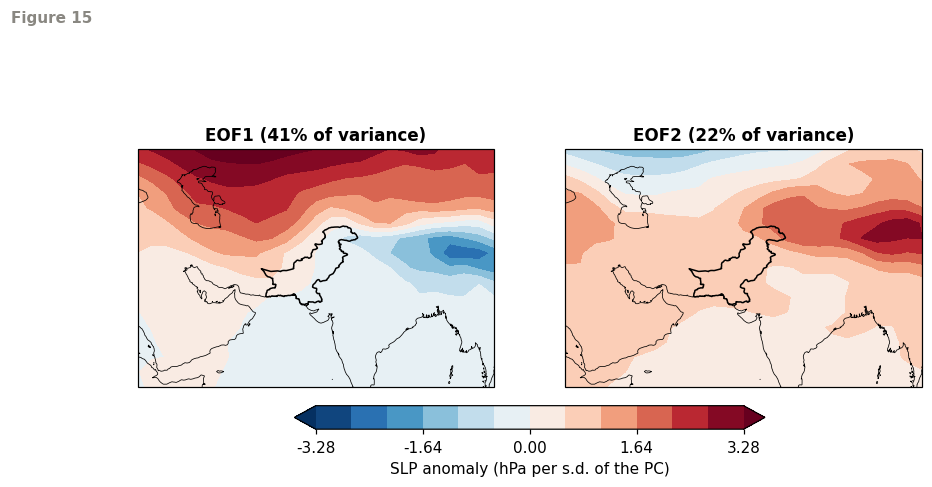

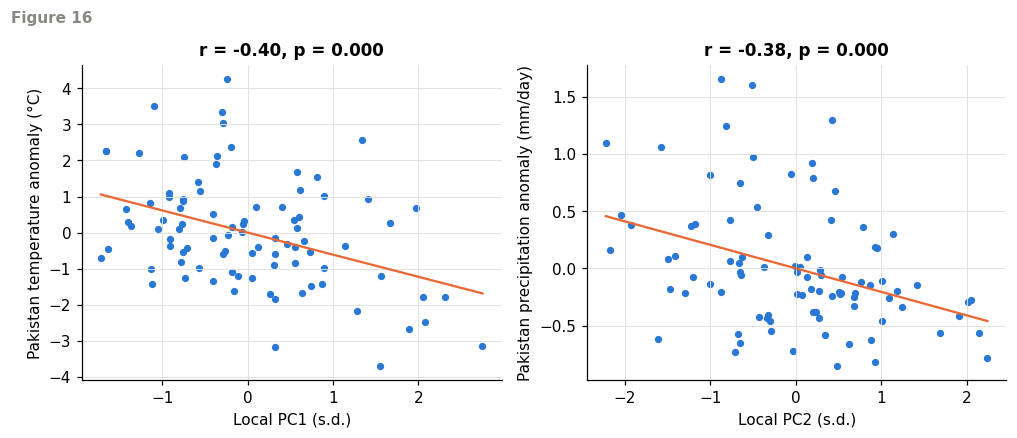

In [31]:
plot_eofs(local, "15_eofs_pakistan_domain", polar=False, extent=(40, 100, 10, 50))
plot_scatter([(local.pcs_std[:, 0], targets["Pakistan T"].values, "Local PC1 (s.d.)", "Pakistan temperature anomaly (°C)"),
              (local.pcs_std[:, 1], targets["Pakistan P"].values, "Local PC2 (s.d.)", "Pakistan precipitation anomaly (mm/day)")],
             "16_local_scatter")

**Figure 15. The two leading EOFs of the Pakistan-centred domain.** Pressure anomaly per standard deviation of each PC. Pakistan is outlined.

**Figure 16. Pakistan's temperature against local PC1, and precipitation against local PC2.** Each point is one winter month.

**Result.**

- **Local EOF1 (41%)** is high pressure over Central Asia, a southward push of the Siberian High. It goes with colder months in Pakistan (r ≈ −0.40, p < 0.001, 16% of the variance).
- **Local EOF2 (22%)** has centres west and east of Pakistan along the track of the winter westerlies. It goes with drier months (r ≈ −0.38, p < 0.001, 14% of the variance).
- These are same-month links. Part A's table shows the AO does not lead Pakistan by a month either, and Section 12.10 shows the same for regional pressure.
- Which EOF carries the rainfall signal is not fixed. Here, for 1997–2026, it is EOF2. Over the longer 1980–2026 sample of Section 12 it is EOF4 (Figure 18). Section 12.7 shows the same instability across domains.

## 10. How our application compares with the paper's

| Step | Paper, §3.5 | This notebook | Same? |
|---|---|---|---|
| Data | NCEP/NCAR monthly SLP, 2.5° | The same dataset | Yes |
| Season and domain | DJF, north of 20°N | DJF, north of 20°N | Yes |
| Period | 1948–2000 | Run A: 1948–2000. Run B: last 30 winters | Run A yes |
| Seasonal cycle | Monthly means removed | Monthly means removed | Yes |
| Weighting | "cosine of latitude" | √cos on the data (= cos on the covariance) | Yes, see Section 6 |
| Fig. 1 | Spectrum with error bars from eq. (12) | Reproduced | Yes |
| Fig. 2 | EOF1 21% (AO), EOF2 13% | 21.6% and 13.2%, same patterns | Yes |
| Fig. 3 | Standardised PCs with ±1 lines | Reproduced | Yes |
| Sign of PC1 over time | High-over-pole phase early in the record, opposite phase late | Reproduced (cell below) | Yes |
| Use of the modes | Describes the patterns | Uses PC1 as an index for Pakistan, and repeats the EOFs on a regional domain | **Our extension** |
| High-amplitude months | PC beyond ±1, shown only | Used to build composite maps | **Our extension** |
| Domain dependence | Stated as a limitation (§3.4) | Tested, and addressed in Section 12 | **Our extension** |

The replication follows the paper step for step. The application keeps the paper's method and changes only the question: from "what are the hemisphere's modes?" to "which modes matter for Pakistan?".

In [32]:
orient(paper, 0, polar_cap, positive=True)
pc1 = pd.Series(paper.pcs_std[:, 0], paper.time)
print(f"Mean PC1, paper sign: 1948–1970 {pc1[:'1970'].mean():+.2f}, 1989–2000 {pc1['1989':].mean():+.2f}")

Mean PC1, paper sign: 1948–1970 +0.33, 1989–2000 -0.63


## 11. Robustness of the replication

Three checks on how far the paper's result can be trusted.

### 11.1 Error bars with independent months

Eq. (12) treats all $n$ months as independent, but months of the same winter are correlated. With a lag-1 correlation $r_1$ between consecutive winter months, the effective sample size is about $n_\text{eff} = n\,(1 - r_1)/(1 + r_1)$ (the paper's footnote 2 raises this).

In [33]:
def effective_n(res: EOFResult) -> float:
    """n (1 - r1) / (1 + r1), with r1 the mean lag-1 correlation of PC1 and PC2
    between consecutive months of the same winter."""
    winter = res.anom.winter.values
    same = winter[1:] == winter[:-1]
    r1 = np.mean([np.corrcoef(res.pcs[:-1, k][same], res.pcs[1:, k][same])[0, 1] for k in (0, 1)])
    return res.n * (1 - r1) / (1 + r1)


rows = []
for name, res in [("Run A", paper), ("Run B", recent)]:
    n_eff = effective_n(res)
    for label, n_used in [("all months", res.n), ("independent months", n_eff)]:
        err = north_error(res.var_pct, n_used)
        rows.append({"run": name, "samples": label, "n": round(n_used), "EOF1 error %": err[0], "EOF2 error %": err[1],
                     "EOF1 separated": separated(res.var_pct, err)[0], "EOF2 separated": separated(res.var_pct, err)[1]})
keep("north_error_independent_months", pd.DataFrame(rows).set_index(["run", "samples"]))

n  EOF1 error %  EOF2 error %  EOF1 separated  \
run   samples                                                               
Run A all months          159         2.425         1.486            True   
      independent months   69         3.676         2.252            True   
Run B all months           90         3.594         2.036            True   
      independent months   50         4.812         2.725            True   

                          EOF2 separated  
run   samples                             
Run A all months                    True  
      independent months           False  
Run B all months                    True  
      independent months           False

**Result.** The 159 months of Run A behave like about 69 independent ones, so the error bars are about 50% wider. EOF1 stays separated. **EOF2 then overlaps EOF3**, so its pattern can mix with EOF3's.

### 11.2 Resampling winters

A bootstrap asks what we would have found with a different set of winters: draw winters with replacement, keep each winter's months together, and redo the EOF analysis 200 times. The pattern match is $|a_k^\text{resample} \cdot a_k^\text{original}|$ (1 = same map).

In [34]:
def bootstrap_winters(res: EOFResult, B: int = 200, seed: int = 0) -> pd.DataFrame:
    """Redo the EOF analysis on B resamples of whole winters."""
    rng = np.random.default_rng(seed)
    winter = res.anom.winter.values
    groups = [np.where(winter == w)[0] for w in np.unique(winter)]
    rows = []
    for _ in range(B):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        sample = res.anom.isel(time=idx)
        boot = compute_eofs(sample - sample.mean("time"))
        rows.append({"EOF1 %": boot.var_pct[0], "EOF2 %": boot.var_pct[1],
                     "EOF1 match": abs(np.sum(boot.eofs[0] * res.eofs[0])),
                     "EOF2 match": abs(np.sum(boot.eofs[1] * res.eofs[1]))})
    return pd.DataFrame(rows)


boot = {"Run A": bootstrap_winters(paper), "Run B": bootstrap_winters(recent)}

summary = {}
for name, b in boot.items():
    low, high = b.quantile(0.025), b.quantile(0.975)
    summary[name] = {
        "EOF1 %, 95% range": f"{low['EOF1 %']:.1f}–{high['EOF1 %']:.1f}",
        "EOF2 %, 95% range": f"{low['EOF2 %']:.1f}–{high['EOF2 %']:.1f}",
        "EOF1 map match, worst 5%": round(b["EOF1 match"].quantile(0.05), 2),
        "EOF2 map match, worst 5%": round(b["EOF2 match"].quantile(0.05), 2),
    }
keep("bootstrap_summary", pd.DataFrame(summary))

,Run A,Run B
"EOF1 %, 95% range",18.8–26.2,19.0–32.8
"EOF2 %, 95% range",11.9–16.3,11.5–17.1
"EOF1 map match, worst 5%",0.92,0.87
"EOF2 map match, worst 5%",0.67,0.41


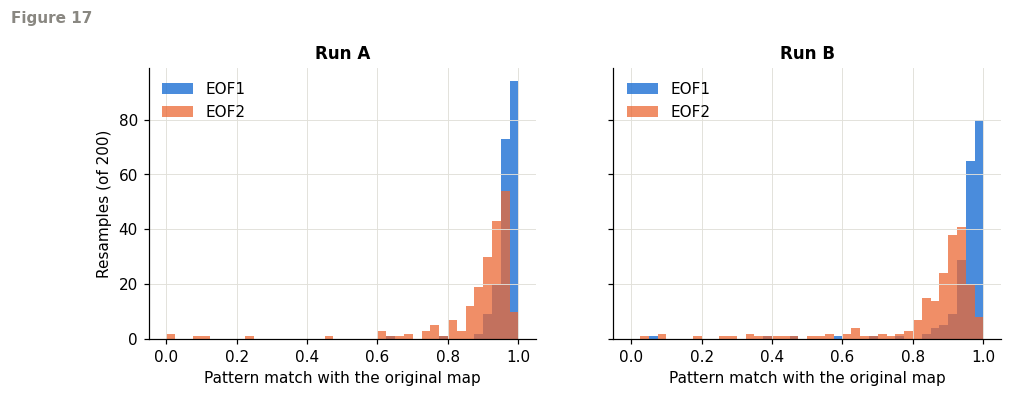

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (name, b) in zip(axes, boot.items()):
    ax.hist(b["EOF1 match"], bins=np.linspace(0, 1, 41), color=BLUE, alpha=0.85, label="EOF1")
    ax.hist(b["EOF2 match"], bins=np.linspace(0, 1, 41), color=ORANGE, alpha=0.75, label="EOF2")
    ax.set(xlabel="Pattern match with the original map", title=name)
    ax.legend(loc="upper left")
axes[0].set_ylabel("Resamples (of 200)")
show("17_bootstrap_pattern_match")

**Figure 17. How much the EOF maps change when the winters are resampled.** Distribution of the pattern match over 200 resamples. Values near 1 mean the map is stable.

**Result.** The percentages are ranges, not single numbers (EOF1 about 19–26% for 1948–2000). EOF1's map is stable. EOF2's map is not: with 30 winters its worst resamples match the original at only about 0.4.

### 11.3 Other choices

In [36]:
anom_a = anomalies(select_winters(nh, *PAPER_PERIOD))
rows = {"as in the paper": paper.var_pct[:2]}

# Noise: shuffle each grid point's months independently, which destroys any shared pattern
rng = np.random.default_rng(1)
noise = [compute_eofs(anom_a.copy(data=rng.permuted(anom_a.values, axis=0))).var_pct[:2] for _ in range(20)]
rows["pure noise (largest of 20 shuffles)"] = np.max(noise, axis=0)

# Trend: remove a straight line at every grid point first
fit = anom_a.polyfit("time", 1).polyfit_coefficients
rows["trend removed first"] = compute_eofs(anom_a - xr.polyval(anom_a.time, fit)).var_pct[:2]

# Complete winters only (1948/49 to 1999/2000), and a domain that starts at the equator
rows["complete winters only"] = compute_eofs(anomalies(select_winters(nh, "1948-12", "2000-02"))).var_pct[:2]
rows["domain from 0°N"] = compute_eofs(anomalies(select_winters(slp.sel(lat=slice(0, 90)), *PAPER_PERIOD))).var_pct[:2]

# 30 winters before and after satellites
rows["winters 1949–1978"] = compute_eofs(anomalies(select_winters(nh, "1948-12", "1978-02"))).var_pct[:2]
rows["winters 1979–2008"] = compute_eofs(anomalies(select_winters(nh, "1978-12", "2008-02"))).var_pct[:2]

keep("robustness_other_choices", pd.DataFrame(rows, index=["EOF1 %", "EOF2 %"]).T.round(1))

,EOF1 %,EOF2 %
as in the paper,21.6,13.2
pure noise (largest of 20 shuffles),1.0,1.0
trend removed first,21.5,12.3
complete winters only,21.7,13.3
domain from 0°N,21.3,13.3
winters 1949–1978,21.9,11.3
winters 1979–2008,22.4,14.6


**Result.** The leading modes are far above noise (about 1%). Trend, half winters and the 20°N boundary each change the percentages by less than one point. EOF2 differs between the pre- and post-satellite periods, within its error bars.

## 12. Research gap: variance is not relevance

### 12.1 The gap

Recent work ties Pakistan's winters to ENSO and the Indian Ocean (Karim et al. 2023; Najeeb et al. 2026), to several climate indices at once (Rebi et al. 2023), and to western disturbances steered by the subtropical jet (Hunt 2024; Hunt et al. 2025). Abbas et al. (2023) describe the trends and extremes of winter precipitation. Three things are untested in this literature:

1. **Out-of-sample skill.** Links are fitted and scored on the same winters. Najeeb et al. (2026) propose their precipitation index for seasonal prediction but do not test it on unseen years.
2. **Domain choice.** EOF patterns change with the analyst's domain and period, and modes of similar variance can swap order (Shields et al. 2026; Hannachi 2004, §3.4).
3. **Variance ranking.** Indices and leading EOFs are chosen because they dominate the *pressure* field, not because they matter for *Pakistan*.

### 12.2 Design of the experiment

| Choice | What we use | Why |
|---|---|---|
| **Question** | How much of Pakistan's monthly winter anomalies do pressure patterns explain in winters they have not seen? | In-sample correlations are optimistic |
| **Predictor field** | SLP over the Pakistan-centred box | The same field and box as Section 9, so results compare directly |
| **Temperature target** | GHCN-CAMS station temperature over Pakistan | Independent of the reanalysis that supplies the pressure, so the link is not built in by one model |
| **Rainfall targets** | GPCP over Pakistan, and over Pakistan north of 31°N | GPCP sees the mountains. The north is where winter rain and snow falls |
| **Period** | December 1979 to the last winter (47 winters, 141 months) | The satellite era, common to all datasets. Earlier data are tested in 12.9 |
| **Validation** | Leave one winter out. Climatology, patterns and regression are refitted each time | Months of one winter are correlated, so whole winters are left out. Refitting everything prevents information leaking from the predicted winter |
| **Skill** | Cross-validated $R^2 = 1 - \sum (y - \hat y)^2 / \sum y^2$ | Share of variance explained in unseen winters. Zero or below means no better than climatology |
| **Uncertainty** | Bootstrap over winters, 2000 resamples | Gives a 95% interval without assuming independent months |

**Models compared**

| Model | Patterns chosen by | Represents |
|---|---|---|
| AO | Variance of hemispheric pressure | Hemispheric indices |
| Siberian High indices | Fixed box: intensity, latitude, longitude | The centres-of-action approach (our simplified version) |
| Regional EOFs 1–3 and 1–10 | Variance of regional pressure | The paper's method |
| **3 target-oriented modes** | **Covariance with the Pakistan series** | Our proposal. The first mode is the covariance map $X'^T_w y$ (SVD analysis with one target). The next ones repeat this on what is left (partial least squares). Three are fixed in advance |

In [37]:
def centre(A: np.ndarray, month: np.ndarray, fit: np.ndarray) -> np.ndarray:
    """Subtract calendar-month means estimated only from the rows where `fit` is True."""
    A = A.copy()
    for m in np.unique(month):
        A[month == m] -= A[fit & (month == m)].mean(axis=0)
    return A


def linear_model(X_train, y_train, X_test) -> np.ndarray:
    """Least-squares regression of y on the columns of X."""
    return X_test @ np.linalg.lstsq(X_train, y_train, rcond=None)[0]


def eof_model(k: int):
    """Regression of y on the leading k EOFs of X."""
    def predict(X_train, y_train, X_test):
        U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
        return X_test @ Vt[:k].T @ (U[:, :k].T @ y_train / s[:k])
    return predict


def target_patterns(X: np.ndarray, y: np.ndarray, k: int) -> np.ndarray:
    """k orthonormal patterns (columns) ordered by covariance with y (partial least squares).

    The first is the covariance map X'y. Each next one is X'X applied to the previous.
    """
    patterns = [X.T @ y]
    for _ in range(k - 1):
        nxt = X.T @ (X @ patterns[-1])
        patterns.append(nxt / np.linalg.norm(nxt))
    return np.linalg.qr(np.array(patterns).T)[0]


def target_model(k: int):
    """Regression of y on k target-oriented modes of X."""
    def predict(X_train, y_train, X_test):
        Q = target_patterns(X_train, y_train, k)
        return linear_model(X_train @ Q, y_train, X_test @ Q)
    return predict


def cross_validate(X, y, winter, month, model) -> np.ndarray:
    """Predict each winter from a model fitted on all the other winters."""
    pred = np.empty_like(y)
    for w in np.unique(winter):
        test = winter == w
        Xc, yc = centre(X, month, ~test), centre(y, month, ~test)
        pred[test] = model(Xc[~test], yc[~test], Xc[test])
    return pred


def r_squared(obs: np.ndarray, pred: np.ndarray) -> float:
    """Share of variance explained; zero or below means no better than climatology."""
    return 1 - np.sum((obs - pred) ** 2) / np.sum(obs**2)


def bootstrap_interval(obs, pred, winter, baseline=None, B: int = 2000, seed: int = 0) -> tuple[float, float]:
    """95% interval of the cross-validated R^2, resampling whole winters.

    With `baseline` (another model's predictions) it is the interval of the R^2 difference.
    """
    rng = np.random.default_rng(seed)
    groups = [np.where(winter == w)[0] for w in np.unique(winter)]
    values = []
    for _ in range(B):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        value = r_squared(obs[idx], pred[idx])
        values.append(value if baseline is None else value - r_squared(obs[idx], baseline[idx]))
    return tuple(np.percentile(values, [2.5, 97.5]))

### 12.3 Data for the experiment

In [38]:
START, END = "1979-12", LAST_30[1]


def pressure_matrix(region: dict, start: str = START, end: str = END, name: str = "slp") -> np.ndarray:
    """Area-weighted DJF pressure of a region as an (n, p) matrix."""
    field = select_winters(select_box(open_field(name), **region), start, end)
    return (field.values * area_weights(field)).reshape(field.sizes["time"], -1)


def siberian_high_indices(start: str = START, end: str = END) -> np.ndarray:
    """Columns: intensity (mean SLP over 40-65N, 80-120E), and the latitude and longitude
    of the centre of the pressure above 1020 hPa over 30-70N, 60-140E."""
    core = select_winters(select_box(slp, lat=(40, 65), lon=(80, 120)), start, end)
    intensity = core.weighted(np.cos(np.deg2rad(core.lat))).mean(("lat", "lon"))
    wide = select_winters(select_box(slp, lat=(30, 70), lon=(60, 140)), start, end)
    excess = (wide - 1020).clip(min=0) * np.cos(np.deg2rad(wide.lat))
    centre_lat = (excess * wide.lat).sum(("lat", "lon")) / excess.sum(("lat", "lon"))
    centre_lon = (excess * wide.lon).sum(("lat", "lon")) / excess.sum(("lat", "lon"))
    return np.c_[intensity, centre_lat, centre_lon]


def pakistan_series(name: str, north_only: bool = False, start: str = START, end: str = END) -> pd.Series:
    """DJF monthly mean of a dataset over Pakistan, or over Pakistan north of 31N."""
    field = select_winters(select_box(open_field(name), lat=(20, 40), lon=(58, 80)), start, end)
    frac = country_fraction(field.lat.values, field.lon.values)
    if north_only:
        frac = frac * (field.lat.values >= 31)[:, None]
    return region_mean(field, frac)


def make_case(name: str, north_only: bool = False, start: str = START, end: str = END) -> dict:
    """Target series with its dates, month, winter and anomalies, ready for cross-validation."""
    y = pakistan_series(name, north_only, start, end)
    month = y.index.month.values
    return dict(time=y.index, y=y.values, month=month, winter=(y.index.year + (y.index.month == 12)).values,
                obs=centre(y.values, month, np.ones(len(y), dtype=bool)))


data = {
    "Temperature, Pakistan": make_case("air_land"),
    "Rainfall, Pakistan": make_case("precip"),
    "Rainfall, northern Pakistan": make_case("precip", north_only=True),
}
predictors = {
    "regional": pressure_matrix(PAKISTAN_SLP),
    "hemispheric": pressure_matrix(NH_20N),
    "siberian": siberian_high_indices(),
}
MONTH = data["Rainfall, Pakistan"]["month"]             # calendar month of every row, the same for all targets
n_winters = len(MONTH) // 3
print(f"{n_winters} winters, {len(MONTH)} months; "
      f"regional predictor matrix {predictors['regional'].shape}")

47 winters, 141 months; regional predictor matrix (141, 425)


### 12.4 Result 1: in-sample fit against out-of-sample skill

In [39]:
MODELS = {                                          # label -> (predictor, model)
    "AO (hemispheric EOF1)": ("hemispheric", eof_model(1)),
    "Siberian High indices": ("siberian", linear_model),
    "Regional EOFs 1–3": ("regional", eof_model(3)),
    "Regional EOFs 1–10": ("regional", eof_model(10)),
    "3 target-oriented modes": ("regional", target_model(3)),
}

rows, predictions = [], {}
for case, d in data.items():
    everything = np.ones(len(d["y"]), dtype=bool)
    for label, (predictor, model) in MODELS.items():
        X = predictors[predictor]
        X_all = centre(X, d["month"], everything)
        pred = predictions[case, label] = cross_validate(X, d["y"], d["winter"], d["month"], model)
        low, high = bootstrap_interval(d["obs"], pred, d["winter"])
        rows.append({"target": case, "model": label,
                     "R² in-sample": r_squared(d["obs"], model(X_all, d["obs"], X_all)),
                     "R² cross-validated": r_squared(d["obs"], pred), "95% low": low, "95% high": high})
skill = keep("skill_in_sample_vs_cross_validated", pd.DataFrame(rows).set_index(["target", "model"]))
display(skill.round(2))

gain = {}
for case, d in data.items():
    target, eofs = predictions[case, "3 target-oriented modes"], predictions[case, "Regional EOFs 1–3"]
    low, high = bootstrap_interval(d["obs"], target, d["winter"], baseline=eofs)
    gain[case] = {"gain in R²": r_squared(d["obs"], target) - r_squared(d["obs"], eofs), "95% low": low, "95% high": high}
print("Gain of 3 target-oriented modes over 3 EOFs (same number of patterns), cross-validated:")
display(keep("gain_target_modes_over_eofs", pd.DataFrame(gain).T).round(2))

# Observed anomalies and every model's cross-validated prediction, month by month, for the review bundle
cv_series = pd.concat({case: pd.DataFrame({"observed": d["obs"], **{m: predictions[case, m] for m in MODELS}}, index=d["time"])
                       for case, d in data.items()}, names=["target", "month"])
keep("cross_validated_predictions", cv_series);

R² in-sample  \
target                      model                                   
Temperature, Pakistan       AO (hemispheric EOF1)            0.00   
                            Siberian High indices            0.03   
                            Regional EOFs 1–3                0.16   
                            Regional EOFs 1–10               0.38   
                            3 target-oriented modes          0.47   
Rainfall, Pakistan          AO (hemispheric EOF1)            0.00   
                            Siberian High indices            0.06   
                            Regional EOFs 1–3                0.07   
                            Regional EOFs 1–10               0.36   
                            3 target-oriented modes          0.35   
Rainfall, northern Pakistan AO (hemispheric EOF1)            0.00   
                            Siberian High indices            0.05   
                            Regional EOFs 1–3                0.09   
                            Regional EOFs 1–10               0.41   
                            3 target-oriented modes          0.39   

                                                     R² cross-validated  \
target                      model                                         
Temperature, Pakistan       AO (hemispheric EOF1)                 -0.01   
                            Siberian High indices                 -0.03   
                            Regional EOFs 1–3                      0.10   
                            Regional EOFs 1–10                     0.23   
                            3 target-oriented modes                0.32   
Rainfall, Pakistan          AO (hemispheric EOF1)                 -0.01   
                            Siberian High indices                 -0.00   
                            Regional EOFs 1–3                      0.01   
                            Regional EOFs 1–10                     0.26   
                            3 target-oriented modes                0.25   
Rainfall, northern Pakistan AO (hemispheric EOF1)                 -0.01   
                            Siberian High indices                 -0.01   
                            Regional EOFs 1–3                      0.03   
                            Regional EOFs 1–10                     0.32   
                            3 target-oriented modes                0.31   

                                                     95% low  95% high  
target                      model                                       
Temperature, Pakistan       AO (hemispheric EOF1)      -0.03      0.01  
                            Siberian High indices      -0.11      0.04  
                            Regional EOFs 1–3          -0.07      0.25  
                            Regional EOFs 1–10          0.00      0.40  
                            3 target-oriented modes     0.11      0.50  
Rainfall, Pakistan          AO (hemispheric EOF1)      -0.03      0.01  
                            Siberian High indices      -0.11      0.10  
                            Regional EOFs 1–3          -0.11      0.11  
                            Regional EOFs 1–10          0.12      0.37  
                            3 target-oriented modes     0.11      0.36  
Rainfall, northern Pakistan AO (hemispheric EOF1)      -0.02      0.00  
                            Siberian High indices      -0.13      0.08  
                            Regional EOFs 1–3          -0.10      0.15  
                            Regional EOFs 1–10          0.19      0.43  
                            3 target-oriented modes     0.16      0.43

Gain of 3 target-oriented modes over 3 EOFs (same number of patterns), cross-validated:


,gain in R²,95% low,95% high
"Temperature, Pakistan",0.22,0.03,0.40
"Rainfall, Pakistan",0.24,0.08,0.41
"Rainfall, northern Pakistan",0.28,0.11,0.45


**Result.**

- **The AO and the Siberian High indices have no out-of-sample skill** at the monthly scale ($R^2 \le 0$). The Siberian High indices fit 3–6% in-sample and lose all of it under cross-validation.
- **The three leading regional EOFs hold 74% of the pressure variance and explain 1–3% of unseen rainfall.** Their intervals include zero for all three targets.
- **Three target-oriented modes explain 25–32%**, with intervals clear of zero. With the same number of patterns they beat the three leading EOFs by 0.22 to 0.28, and that gain is itself clear of zero.
- Ten EOFs reach the same skill for rainfall (0.26 and 0.32 against 0.25 and 0.31), and lower skill for temperature (0.23 against 0.33). Target-oriented modes are the more compact description, not a different source of information.
- In-sample values are always higher than cross-validated ones. This is the optimism that same-sample correlations carry.

Our Siberian High indices follow the centres-of-action idea but are our own simplified, monthly, country-scale version. They are not a replication of the earlier centres-of-action studies, which used winter means, a northern region and an added ENSO or Indian Ocean index.

### 12.5 Result 2: where the signal sits in the EOF spectrum

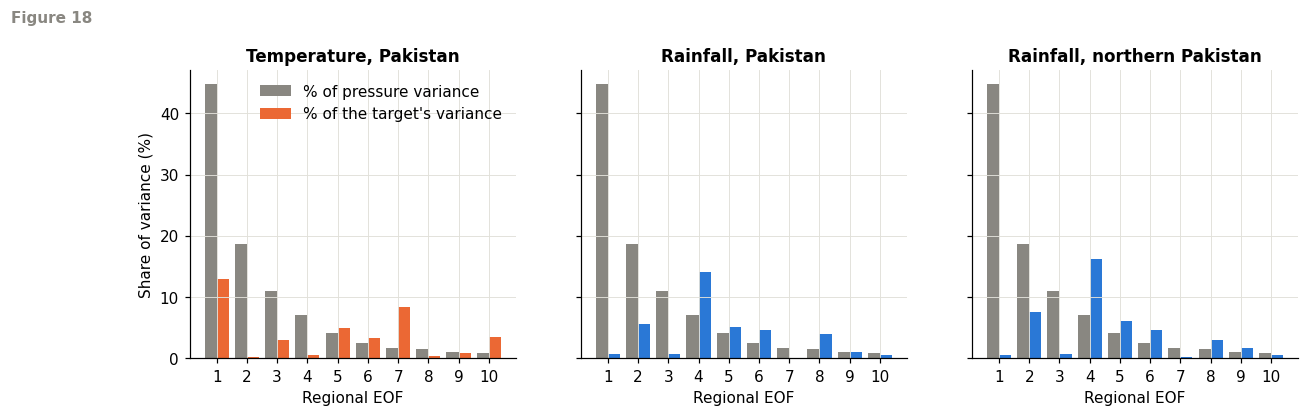

In [40]:
X_all = centre(predictors["regional"], MONTH, np.ones(len(MONTH), dtype=bool))
U, s, _ = np.linalg.svd(X_all, full_matrices=False)
pressure_share = 100 * s[:10] ** 2 / np.sum(s**2)
rank = np.arange(1, 11)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (case, d), color in zip(axes, data.items(), [ORANGE, BLUE, BLUE]):
    target_share = 100 * (U[:, :10].T @ d["obs"]) ** 2 / np.sum(d["obs"] ** 2)
    ax.bar(rank - 0.2, pressure_share, 0.4, color=GREY, label="% of pressure variance")
    ax.bar(rank + 0.2, target_share, 0.4, color=color, label="% of the target's variance")
    ax.set(xlabel="Regional EOF", xticks=rank, title=case)
axes[0].legend()
axes[0].set_ylabel("Share of variance (%)")
show("18_signal_in_eof_spectrum")
keep("pressure_variance_by_eof", pd.Series(pressure_share, index=rank, name="% of pressure variance").to_frame());

**Figure 18. Where the signal sits in the EOF spectrum.** For each regional EOF: the share of pressure variance it explains (grey) against the share of the target's variance it explains (colour, in-sample $r^2$).

**Result.** The two rankings disagree. For rainfall, EOF1 holds 45% of the pressure variance and almost none of the signal, while **EOF4 holds 7% of the pressure variance and 14–16% of the rainfall variance**. For temperature, EOF1 matters most, but EOF7 (2% of the pressure variance) comes second. Truncating by variance cuts into the signal.

This also explains an apparent conflict with Section 9, where local EOF2 went with drier months. That was 1997–2026. Over 1980–2026 the rainfall signal sits mainly in EOF4, with a smaller share in EOF2. The variance ranking of the modes, and so their numbers, shifts with the sample.

### 12.6 Result 3: skill against the number of modes

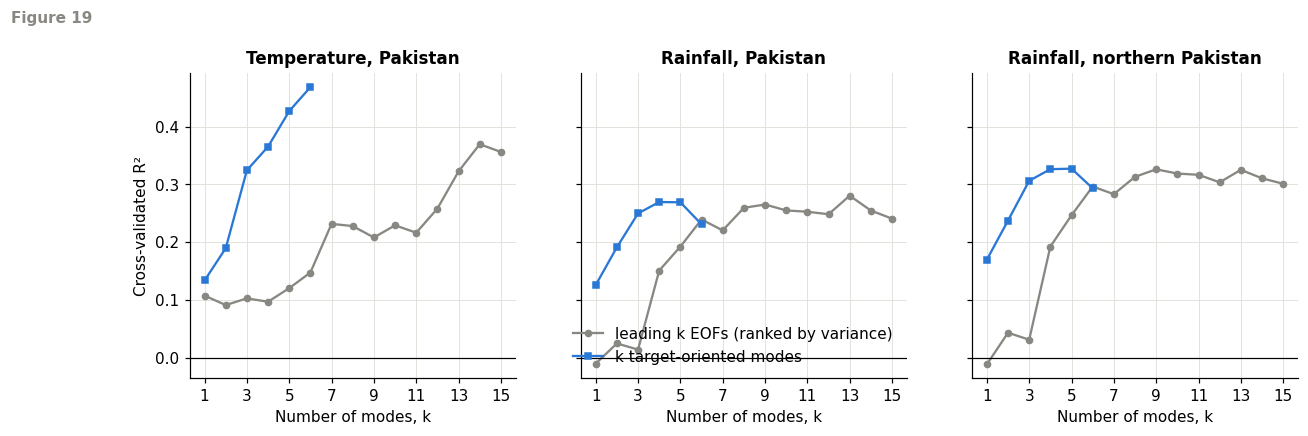

In [41]:
eof_ks, target_ks = np.arange(1, 16), np.arange(1, 7)
curves = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (case, d) in zip(axes, data.items()):
    args = (predictors["regional"], d["y"], d["winter"], d["month"])
    curves[case, "EOFs"] = pd.Series([r_squared(d["obs"], cross_validate(*args, eof_model(k))) for k in eof_ks], eof_ks)
    curves[case, "target-oriented"] = pd.Series([r_squared(d["obs"], cross_validate(*args, target_model(k))) for k in target_ks], target_ks)
    ax.plot(curves[case, "EOFs"], color=GREY, marker="o", ms=4, label="leading k EOFs (ranked by variance)")
    ax.plot(curves[case, "target-oriented"], color=BLUE, marker="s", ms=4, label="k target-oriented modes")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel="Number of modes, k", xticks=eof_ks[::2], title=case)
axes[0].set_ylabel("Cross-validated R²")
axes[1].legend(loc="lower right")
show("19_skill_vs_number_of_modes")
keep("skill_vs_number_of_modes", pd.DataFrame(curves).rename_axis("k"));

**Figure 19. Cross-validated skill against the number of modes.** Grey: regression on the leading k EOFs. Blue: k target-oriented modes. The horizontal line is climatology.

**Result.** For rainfall, skill stays near zero until EOF4 enters and levels off from about six EOFs on. Target-oriented modes reach that level with three patterns. For temperature, skill keeps rising with more modes. That is partly built in: over high ground, sea level pressure is computed from surface pressure using temperature, so fine pressure detail near Pakistan carries temperature information. We therefore fix three target-oriented modes in advance instead of picking the best-looking $k$.

### 12.7 Result 4: does the answer depend on the domain?

The analysis is repeated on 81 domains (each edge of the box moved by ±10°). For each we record which of the first five EOFs correlates best with the target, and the cross-validated skill.

In [42]:
DOMAINS = [dict(lat=(south, north), lon=(west, east))
           for south in (0, 10, 20) for north in (40, 50, 60) for west in (30, 40, 50) for east in (90, 100, 110)]

sensitivity = []
for region in DOMAINS:
    X = pressure_matrix(region)
    U = np.linalg.svd(centre(X, MONTH, np.ones(len(X), dtype=bool)), full_matrices=False)[0]
    for case, d in data.items():
        args = (X, d["y"], d["winter"], d["month"])
        sensitivity.append({"target": case, "best EOF": 1 + np.abs(U[:, :5].T @ d["obs"]).argmax(),
                            "Regional EOFs 1–3": r_squared(d["obs"], cross_validate(*args, eof_model(3))),
                            "Regional EOFs 1–10": r_squared(d["obs"], cross_validate(*args, eof_model(10))),
                            "3 target-oriented modes": r_squared(d["obs"], cross_validate(*args, target_model(3)))})
sensitivity = keep("domain_sensitivity_81_domains", pd.DataFrame(sensitivity))

print("Number of domains (of 81) in which each EOF is the one best correlated with the target:")
display(sensitivity.groupby("target")["best EOF"].value_counts().unstack(fill_value=0))
print("Cross-validated R² across the 81 domains:")
sensitivity.drop(columns="best EOF").groupby("target").agg(["min", "median", "max"]).round(2)

Number of domains (of 81) in which each EOF is the one best correlated with the target:


best EOF,1,2,3,4,5
target,,,,,
"Rainfall, Pakistan",0,1,34,30,16
"Rainfall, northern Pakistan",0,2,34,29,16
"Temperature, Pakistan",32,38,8,0,3


Cross-validated R² across the 81 domains:


Regional EOFs 1–3              Regional EOFs 1–10  \
                                          min median   max                min   
target                                                                          
Rainfall, Pakistan                      -0.04   0.04  0.24               0.21   
Rainfall, northern Pakistan             -0.04   0.06  0.30               0.28   
Temperature, Pakistan                    0.08   0.10  0.17               0.13   

                                         3 target-oriented modes               
                            median   max                     min median   max  
target                                                                         
Rainfall, Pakistan            0.26  0.34                    0.20   0.26  0.33  
Rainfall, northern Pakistan   0.31  0.38                    0.23   0.31  0.36  
Temperature, Pakistan         0.27  0.49                    0.20   0.29  0.39

**Result.** Which EOF "controls" Pakistan depends on the box. For rainfall it is EOF3 in 34 domains, EOF4 in about 30 and EOF5 in 16. For temperature it moves between EOF1 and EOF2. The rainfall skill of the leading three EOFs swings with it (−0.04 to 0.30). The skill of three target-oriented modes stays between 0.20 and 0.39 for every target and domain. **The label of the mode is an artefact of the domain. The information is not.**

### 12.8 Result 5: stable in time?

Fit three target-oriented modes on one half of the winters and score them on the other half, each half with its own climatology.

In [43]:
def split_sample(X, d: dict, model) -> tuple[float, float]:
    """R^2 when fitting on the early half and scoring on the late half, and the reverse."""
    early = d["winter"] <= np.median(np.unique(d["winter"]))
    half = {}
    for name, rows_ in [("early", early), ("late", ~early)]:
        everything = np.ones(rows_.sum(), dtype=bool)
        half[name] = (centre(X[rows_], d["month"][rows_], everything), centre(d["y"][rows_], d["month"][rows_], everything))
    return (r_squared(half["late"][1], model(*half["early"], half["late"][0])),
            r_squared(half["early"][1], model(*half["late"], half["early"][0])))


keep("split_sample", pd.DataFrame({case: split_sample(predictors["regional"], d, target_model(3)) for case, d in data.items()},
                                  index=["fit early, score late", "fit late, score early"]).T).round(2)

,"fit early, score late","fit late, score early"
"Temperature, Pakistan",0.17,0.19
"Rainfall, Pakistan",0.26,0.17
"Rainfall, northern Pakistan",0.32,0.30


**Result.** The relation holds in both directions for all three targets. It is most stable for rainfall over northern Pakistan, where a model fitted on either half explains about 30% of the other.

### 12.9 Result 6: other datasets and a longer record

The same model (three target-oriented modes) with a second dataset for each target, and with the full record back to 1949. The last two columns describe the target series itself: its correlation with the main dataset, and the ratio of its standard deviation in the late and early halves.

In [44]:
ALTERNATIVES = {       # label -> (main case, dataset, north only, first December)
    "Temperature, Pakistan: NCEP/NCAR": ("Temperature, Pakistan", "air", False, START),
    "Temperature, Pakistan: GHCN-CAMS from 1949": ("Temperature, Pakistan", "air_land", False, "1948-12"),
    "Rainfall, Pakistan: PREC/L": ("Rainfall, Pakistan", "precip_land", False, START),
    "Rainfall, northern Pakistan: PREC/L": ("Rainfall, northern Pakistan", "precip_land", True, START),
}


def describe(label: str, d: dict, X: np.ndarray, main: dict | None = None, same_dataset: bool = False) -> dict:
    early = d["winter"] <= np.median(np.unique(d["winter"]))
    pred = cross_validate(X, d["y"], d["winter"], d["month"], target_model(3))
    forward, backward = split_sample(X, d, target_model(3))
    corr = np.nan
    if main is not None and not same_dataset:                        # correlation over the months both series cover
        both = pd.concat([pd.Series(d["obs"], d["time"]), pd.Series(main["obs"], main["time"])], axis=1, join="inner")
        corr = both.corr().iloc[0, 1]
    return {"series": label, "winters": len(np.unique(d["winter"])),
            "R² cross-validated": r_squared(d["obs"], pred),
            "fit early, score late": forward, "fit late, score early": backward,
            "correlation with main dataset": corr,
            "s.d. late / early": d["obs"][~early].std() / d["obs"][early].std()}


rows = [describe(f"{case}: main dataset", d, predictors["regional"]) for case, d in data.items()]
for label, (case, name, north_only, start) in ALTERNATIVES.items():
    end = f"{min(int(END[:4]), last_complete_winter(name))}-02"     # a dataset may end before the others
    rows.append(describe(label, make_case(name, north_only, start, end), pressure_matrix(PAKISTAN_SLP, start, end), data[case],
                         same_dataset=(name == "air_land")))   # the 1949 run is the main temperature dataset, longer
keep("other_datasets_and_longer_record", pd.DataFrame(rows).set_index("series").sort_index()).round(2)

,winters,R² cross-validated,"fit early, score late","fit late, score early",correlation with main dataset,s.d. late / early
series,,,,,,
"Rainfall, Pakistan: PREC/L",47,0.11,-0.01,-0.04,0.63,1.73
"Rainfall, Pakistan: main dataset",47,0.25,0.26,0.17,NaN,1.48
"Rainfall, northern Pakistan: PREC/L",47,-0.01,-0.06,-0.06,0.44,1.84
"Rainfall, northern Pakistan: main dataset",47,0.31,0.32,0.30,NaN,1.31
"Temperature, Pakistan: GHCN-CAMS from 1949",78,0.29,0.13,0.39,NaN,0.91
"Temperature, Pakistan: NCEP/NCAR",47,0.41,0.31,0.36,0.81,1.34
"Temperature, Pakistan: main dataset",47,0.32,0.17,0.19,NaN,1.29


**Result.**

- **Temperature.** A second dataset (NCEP/NCAR) gives the same or higher skill and transfers both ways. With the record extended to 1949, a model fitted on recent winters still describes the early ones, but the reverse is weak (0.13). The instability seen in long records therefore comes from the years before 1980, when both pressure analyses and station coverage over Asia were poorer. This is why the satellite era is the main period.
- **Rainfall.** PREC/L gives no stable skill, and it agrees poorly with GPCP (r = 0.63 for Pakistan, 0.44 in the north). Its standard deviation is 1.7 to 1.8 times larger in the late half than in the early half, against 1.3 to 1.5 for GPCP. A jump of that size points to a change in gauge coverage. The two datasets cannot both be right, and only station records from the Pakistan Meteorological Department can settle it. The rainfall results rest on GPCP.

### 12.10 Result 7: is it a forecast?

Ways to predict a month ahead, all cross-validated: this month's regional pressure (one target-oriented mode), this month's Siberian High indices, persistence (this month's anomaly of the target itself), and this month's Niño 3.4 index.

In [45]:
nino = load_nino34()
rows = {}
for case, d in data.items():
    same_winter = d["winter"][1:] == d["winter"][:-1]              # pairs (this month, next month)
    y_next, month_next, winter_next = d["y"][1:][same_winter], d["month"][1:][same_winter], d["winter"][1:][same_winter]
    obs_next = centre(y_next, month_next, np.ones(len(y_next), dtype=bool))
    lagged = {"regional pressure": (predictors["regional"][:-1][same_winter], target_model(1)),
              "Siberian High indices": (predictors["siberian"][:-1][same_winter], linear_model),
              "persistence": (d["y"][:-1][same_winter][:, None], linear_model)}
    if nino is not None and nino.reindex(d["time"]).notna().all():
        lagged["Niño 3.4"] = (nino.reindex(d["time"]).values[:-1][same_winter][:, None], linear_model)
    rows[case] = {name: r_squared(obs_next, cross_validate(X, y_next, winter_next, month_next, model))
                  for name, (X, model) in lagged.items()}
if nino is None:
    NOTES.append("nina34.anom.data not found: Niño 3.4 forecast test skipped")
keep("one_month_lead_forecast", pd.DataFrame(rows).T).round(2)

,regional pressure,Siberian High indices,persistence,Niño 3.4
"Temperature, Pakistan",-0.11,-0.05,0.11,-0.01
"Rainfall, Pakistan",-0.01,-0.04,-0.03,-0.01
"Rainfall, northern Pakistan",-0.02,-0.05,-0.00,-0.01


**Result.** No predictor has skill a month ahead. Regional pressure, the Siberian High indices and Niño 3.4 all score at or below zero. The only exception is weak persistence of temperature (0.11). November pressure as a predictor of the winter mean, and hemispheric instead of regional pressure, gave the same outcome (not shown). **Pressure explains a month's weather but does not forecast the next.**

Niño 3.4 failing here does not rule out ENSO. ENSO acts on the seasonal mean, and a one-month lead on monthly anomalies is a hard test. A forecast study should use seasonal means and start from autumn sea surface temperature (ENSO and the Indian Ocean Dipole).

### 12.11 A second pressure dataset

The main result repeated with NCEP-DOE Reanalysis 2 pressure, over the period it covers.

In [46]:
if (DATA_DIR / DATASETS["slp_r2"][0]).exists():
    try:
        r2_end = min(pd.Timestamp(END), pd.Timestamp(open_field("slp_r2").time.values[-1])).strftime("%Y-%m")
        X_r2 = pressure_matrix(PAKISTAN_SLP, START, r2_end, name="slp_r2")
        X_r1 = pressure_matrix(PAKISTAN_SLP, START, r2_end)
        rows = {}
        for case, d in data.items():
            keep_rows = slice(0, len(X_r2))
            y, month = d["y"][keep_rows], d["month"][keep_rows]
            obs = centre(y, month, np.ones(len(y), dtype=bool))         # anomalies of the shorter period
            args = (y, d["winter"][keep_rows], month, target_model(3))
            rows[case] = {"NCEP/NCAR": r_squared(obs, cross_validate(X_r1, *args)),
                          "NCEP-DOE R2": r_squared(obs, cross_validate(X_r2, *args))}
        print(f"Common period: December 1979 to {r2_end}, {len(X_r2) // 3} winters")
        display(keep("second_pressure_dataset", pd.DataFrame(rows).T).round(2))
    except Exception as error:                                       # recorded for the review, not fatal
        NOTES.append(f"second pressure dataset failed: {error!r}")
        print("Could not use mslp.mon.mean.nc:", error)
else:
    NOTES.append("mslp.mon.mean.nc not found: second pressure dataset skipped")
    print("mslp.mon.mean.nc not found in data/: skipped.")

Common period: December 1979 to 2025-09, 46 winters


,NCEP/NCAR,NCEP-DOE R2
"Temperature, Pakistan",0.29,0.26
"Rainfall, Pakistan",0.25,0.27
"Rainfall, northern Pakistan",0.31,0.33


### 12.12 The patterns

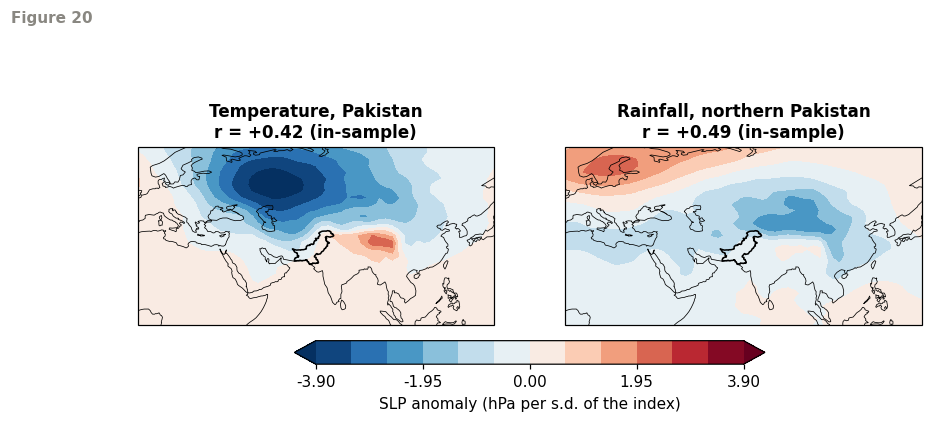

In [47]:
VIEW = dict(lat=(0, 70), lon=(0, 140))
wide = anomalies(select_winters(select_box(slp, **VIEW), START, END))
maps, titles = [], []
for case in ["Temperature, Pakistan", "Rainfall, northern Pakistan"]:
    d = data[case]
    X_all = centre(predictors["regional"], d["month"], np.ones(len(d["y"]), dtype=bool))
    index = X_all @ target_patterns(X_all, d["obs"], 1)[:, 0]
    index = np.sign(np.corrcoef(index, d["obs"])[0, 1]) * (index - index.mean()) / index.std(ddof=1)
    maps.append(np.tensordot(index, wide.values, axes=1) / (len(index) - 1))
    titles.append(f"{case}\nr = {np.corrcoef(index, d['obs'])[0, 1]:+.2f} (in-sample)")
plot_maps(maps, wide.lat.values, wide.lon.values, titles, "SLP anomaly (hPa per s.d. of the index)",
          "20_target_oriented_patterns", polar=False, extent=(0, 140, 0, 70))

**Figure 20. The first target-oriented pattern for temperature and for northern rainfall.** Pressure anomalies regressed on the first target-oriented mode, signed so that a positive index means a warmer or wetter Pakistan. The view is wider than the analysis box (0–70°N, 0–140°E) to show where each pattern comes from.

**Result.** Both patterns are physically familiar, which supports the statistics.

- **Warm months** go with low pressure over Central Asia and Siberia, that is a weak Siberian High, and higher pressure over Tibet. This agrees with Karim et al. (2023), who link warm winters to an anticyclone from north-east Pakistan to Tibet, and with Li et al. (2024), who link East Asian cold extremes to a strong Siberian High. The Siberian High matters, then, but through a pattern that a fixed-box index does not capture month by month.
- **Wet months in the north** go with a trough from Iran across Afghanistan and Pakistan to Tibet and higher pressure over northern Europe: the footprint of western disturbances arriving along the subtropical jet (Hunt 2024; Hunt et al. 2025).

### 12.13 Contribution and limits

**What a paper can claim.**

1. Hemispheric indices, fixed-box Siberian High indices and variance-ranked EOFs explain almost none of Pakistan's monthly winter rainfall out of sample. The relevant circulation sits in low-variance modes.
2. Three target-oriented modes explain 25–32% of unseen monthly rainfall and temperature variance, significantly more than three EOFs, and stably across 81 domains, both halves of the satellite era and two reanalyses (Section 12.11).
3. Which EOF carries the signal is set by the analyst's domain. Cross-validated skill of a mode *set* is the domain-independent quantity to report.
4. The link is diagnostic. Pressure gives no skill one month ahead.

**Limits that remain.**

- **Pressure field.** NCEP-DOE Reanalysis 2 gives the same skill (Section 12.11), but it shares much of its system with Reanalysis 1. Section 13 shows that NCEP and ERA5 pressure trends differ over this region. An upper-air field (500 hPa height or 200 hPa wind) would trace western disturbances better than sea level pressure.
- **Rainfall observations disagree.** The results hold for GPCP and not for PREC/L. Station data are needed.
- **No forecast.** Niño 3.4 at a one-month lead failed too. A forecast needs seasonal means and autumn sea surface temperature predictors, tested with the same cross-validation.
- **Temperature skill is partly built in.** Below high ground, sea level pressure is extrapolated using temperature, so some of the pressure–temperature link is not physical.
- **Benchmark.** Ten EOFs match the target-oriented modes for rainfall. The advantage is compactness and stability, not new information.
- **Monthly means and linear models only.**

## 13. Extension: how much of Pakistan's winter change is the circulation?

### 13.1 The gap

Section 12 shows which pressure patterns explain Pakistan's winter months out of sample. This section uses that result to answer a climate question the literature has not asked:

> **How much of Pakistan's winter warming and rainfall change since 1980 comes from changes in the atmospheric circulation, and how much remains once the circulation is accounted for?**

Pakistan's winters have warmed. Recent studies either describe trends (Rebi et al. 2023; Abbas et al. 2023) or relate year-to-year variability to ocean drivers and indices (Karim et al. 2023; Najeeb et al. 2026). Hunt (2024) finds that western disturbances have become more frequent in January as the subtropical jet strengthened, so part of the rainfall change may itself be circulation-driven. None separates the trend into a part caused by the circulation, for example a weakening Siberian High, and a residual part. The residual is mostly thermodynamic warming, but it can also contain land-surface and other effects.

The tool for this is **dynamical adjustment**. Recent work applies it to European winters (Deser and Phillips 2023), European heat extremes (Vautard et al. 2023), East Asian cold extremes (Li et al. 2024), Northern Hemisphere cold extremes (Lan et al. 2026), and compares methods against a model benchmark (Pfleiderer et al. 2026). We found no application to Pakistan or the western Himalaya.

The split matters for three reasons:

1. **Attribution.** A circulation-driven trend can reverse with the circulation. A thermodynamic one will not.
2. **Detection.** Removing circulation noise narrows the confidence interval of the residual trend, so a forced change can be detected sooner.
3. **Extreme winters.** It shows whether a record warm or dry winter was mainly the weather pattern or mainly the warmer background.

### 13.2 Design

| Choice | What we use | Why |
|---|---|---|
| **Circulation predictor** | Monthly DJF SLP over the Pakistan-centred box, with grid points above 1500 m removed | SLP below high ground is extrapolated from temperature. Removing those points (mostly Tibet) stops warming from showing up as a "circulation" change |
| **Main method** | Three target-oriented (partial least squares) modes, the model Section 12 validated | Fixed in advance, so it is not tuned to the result |
| **Second method** | Constructed circulation analogues, as used by Deser and Phillips (2023): 30 nearest same-month analogues, 100 random subsets of 20 | A different method, so agreement is not an artefact of PLS |
| **Learning the circulation link** | From linearly detrended pressure and target only | The circulation–target relation must not absorb the thermodynamic trend. It is then applied to the actual pressure, trend included |
| **Validation** | Leave one winter out. The climatology, trends, patterns and regression are refitted each time | A month never helps estimate its own circulation part |
| **Trends** | Winter (DJF) means, least squares, 95% intervals with the lag-1 effective sample size (see Method sources) | Standard for short climate series |
| **Check of the method** | Synthetic target with a known circulation and thermodynamic trend, built on the real pressure data | Shows the method recovers a split we know |
| **Sensitivity** | 1 and 5 modes, no mask, two other elevation cut-offs, two other domains, analogues, NCEP/NCAR temperature, NCEP-DOE R2 pressure and ERA5 pressure (12 runs) | Only a result that holds across all of these is reported as robust |

**Decomposition.** For each month, observed anomaly = circulation part + residual. The circulation part is the cross-validated prediction from pressure. The residual is what is left.

### 13.3 Method

The functions below implement the decomposition. Pressure grid points above 1500 m, taken from the NCEP/NCAR surface height, are removed.

In [48]:
ELEV_THRESHOLD = 1500                                  # m; SLP below higher ground is extrapolated

DATA_URLS.update({
    "hgt.sfc.nc": [PSL + "ncep.reanalysis/surface/hgt.sfc.nc",
                   PSL + "ncep.reanalysis.derived/surface/hgt.sfc.nc"],
    "pres.mon.mean.nc": [PSL + "ncep.reanalysis/Monthlies/surface/pres.mon.mean.nc",
                         PSL + "ncep.reanalysis.derived/surface/pres.mon.mean.nc"],
})


def surface_height(region: dict) -> np.ndarray | None:
    """Model surface height (m) on the 2.5° SLP grid of a region, or None if no file is available.

    Uses the NCEP/NCAR surface geopotential height, or else the mean surface pressure
    converted with the standard atmosphere.
    """
    path = fetch("hgt.sfc.nc", required=False)
    if path is not None:
        h = xr.open_dataset(path, decode_times=False)["hgt"].squeeze(drop=True).sortby("lat")
        return select_box(h, **region).values.astype(float)
    path = fetch("pres.mon.mean.nc", required=False)
    if path is not None:
        ps = select_box(xr.open_dataset(path)["pres"].sortby("lat"), **region).mean("time").values.astype(float)
        ps = ps / 100 if np.nanmedian(ps) > 2000 else ps                  # Pa -> hPa
        return 44330.0 * (1 - (ps / 1013.25) ** 0.1903)
    return None


def low_ground(region: dict) -> np.ndarray | None:
    """Mask of the columns of pressure_matrix(region) that lie below ELEV_THRESHOLD."""
    h = surface_height(region)
    return None if h is None else (h <= ELEV_THRESHOLD).ravel()


def decimal_year(time) -> np.ndarray:
    t = pd.DatetimeIndex(time)
    return (t.year + (t.month - 0.5) / 12).values


def remove_trend(A: np.ndarray, t: np.ndarray) -> np.ndarray:
    """Remove a least-squares line in t from each column of A (or from a vector)."""
    G = np.c_[np.ones_like(t), t - t.mean()]
    return A - G @ np.linalg.lstsq(G, A, rcond=None)[0]


# --- the two methods: learn from detrended training data, apply to actual anomalies ---
def pls_adjust(k: int = 3):
    """Circulation part from k target-oriented (PLS) modes."""
    def apply(Xd, yd, month_d, X_new, month_new):
        Q = target_patterns(Xd, yd, k)
        beta = np.linalg.lstsq(Xd @ Q, yd, rcond=None)[0]
        return X_new @ Q @ beta
    return apply


def analogue_adjust(n_analogues: int = 30, n_sub: int = 20, n_draws: int = 100, seed: int = 0):
    """Constructed circulation analogues (as in Deser and Phillips 2023), same calendar month only."""
    def apply(Xd, yd, month_d, X_new, month_new):
        rng = np.random.default_rng(seed)
        out = np.empty(len(X_new))
        for j, (x, m) in enumerate(zip(X_new, month_new)):
            pool = np.where(month_d == m)[0]
            near = pool[np.argsort(np.linalg.norm(Xd[pool] - x, axis=1))[:n_analogues]]
            size = min(n_sub, len(near))
            estimates = []
            for _ in range(n_draws):
                pick = rng.choice(near, size, replace=False)
                w = np.linalg.lstsq(Xd[pick].T, x, rcond=None)[0]       # x ~ sum_i w_i * analogue_i
                estimates.append(w @ yd[pick])
            out[j] = np.mean(estimates)
        return out
    return apply


def dynamical_adjustment(X: np.ndarray, case: dict, method) -> dict:
    """Cross-validated split of a target into circulation part and residual.

    For each winter: the climatology comes from the other winters, the circulation link is
    learnt from their detrended anomalies, and it is applied to this winter's actual anomalies.
    """
    y, month, winter = case["y"], case["month"], case["winter"]
    t = decimal_year(case["time"])
    dyn = np.empty(len(y))
    for w in np.unique(winter):
        test = winter == w
        Xc, yc = centre(X, month, ~test), centre(y, month, ~test)
        Xd, yd = remove_trend(Xc[~test], t[~test]), remove_trend(yc[~test], t[~test])
        dyn[test] = method(Xd, yd, month[~test], Xc[test], month[test])
    return dict(obs=case["obs"], dyn=dyn, res=case["obs"] - dyn, winter=winter, time=case["time"], y=y)


# --- trends of winter means ---
def winter_means(values: np.ndarray, winter: np.ndarray) -> pd.Series:
    return pd.Series(np.asarray(values, dtype=float)).groupby(np.asarray(winter)).mean()


def trend(values, winter) -> dict:
    """Least-squares trend of the winter means per decade, with a 95% interval and p-value
    using the lag-1 effective sample size of the residuals."""
    s = winter_means(values, winter).dropna()
    x, y = s.index.values.astype(float), s.values
    slope, intercept = np.polyfit(x, y, 1)
    resid = y - (slope * x + intercept)
    r1 = float(np.clip(np.corrcoef(resid[:-1], resid[1:])[0, 1], 0, 0.99))
    dof = max(len(y) * (1 - r1) / (1 + r1) - 2, 1)
    se = np.sqrt(np.sum(resid**2) / dof / np.sum((x - x.mean()) ** 2))
    return dict(per_decade=10 * slope, ci95=10 * stats.t.ppf(0.975, dof) * se,
                p=2 * stats.t.sf(abs(slope / se), dof), se=10 * se)


def decomposition_table(results: dict) -> pd.DataFrame:
    """Trends of the observed, circulation and residual parts, and how much variance the circulation explains."""
    rows = {}
    for case, r in results.items():
        T = {part: trend(r[part], r["winter"]) for part in ("obs", "dyn", "res")}
        years = winter_means(r["obs"], r["winter"]).index.values.astype(float)
        obs_w = remove_trend(winter_means(r["obs"], r["winter"]).values, years)
        res_w = remove_trend(winter_means(r["res"], r["winter"]).values, years)
        t = decimal_year(r["time"])
        obs_m, res_m = remove_trend(r["obs"], t), remove_trend(r["res"], t)
        mean_y = np.mean(r["y"])
        row = {}
        for part, label in [("obs", "observed"), ("dyn", "circulation"), ("res", "residual")]:
            row[label, "trend /decade"] = T[part]["per_decade"]
            row[label, "± 95%"] = T[part]["ci95"]
            row[label, "p"] = T[part]["p"]
        row["summary", "circulation share of trend %"] = (
            100 * T["dyn"]["per_decade"] / T["obs"]["per_decade"] if T["obs"]["p"] < 0.1 else np.nan)
        row["summary", "observed trend, % of mean /decade"] = (
            100 * T["obs"]["per_decade"] / mean_y if "Rain" in case and mean_y > 1e-6 else np.nan)
        row["summary", "circulation R², months (detrended)"] = 1 - np.sum(res_m**2) / np.sum(obs_m**2)
        row["summary", "circulation R², winter means (detrended)"] = 1 - np.sum(res_w**2) / np.sum(obs_w**2)
        row["summary", "trend s.e., residual / observed"] = T["res"]["se"] / T["obs"]["se"]
        rows[case] = row
    table = pd.DataFrame(rows).T
    table.columns = pd.MultiIndex.from_tuples(table.columns)
    return table


CASE_SOURCES = {"Temperature, Pakistan": ("air_land", False), "Rainfall, Pakistan": ("precip", False),
                "Rainfall, northern Pakistan": ("precip", True)}
UNITS = {"Temperature, Pakistan": "°C", "Rainfall, Pakistan": "mm/day", "Rainfall, northern Pakistan": "mm/day"}

MASK = low_ground(PAKISTAN_SLP)
if MASK is None:
    NOTES.append("no surface height file: Section 13 runs without the high-ground mask")
    X_MAIN = predictors["regional"]
else:
    X_MAIN = predictors["regional"][:, MASK]
print(f"pressure grid points kept: {X_MAIN.shape[1]} of {predictors['regional'].shape[1]} "
      f"({'below ' + str(ELEV_THRESHOLD) + ' m' if MASK is not None else 'no mask available'})")

downloading hgt.sfc.nc from https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis/surface/hgt.sfc.nc ...
  saved data/hgt.sfc.nc (0 MB)
pressure grid points kept: 330 of 425 (below 1500 m)


### 13.4 Does the method recover a known answer?

Before reading anything into real trends, we test the method on a target whose answer we know. The target is built from the real pressure data: a circulation part (a fixed pattern of the real SLP, so it carries the real circulation trend), plus an imposed residual trend of 0.30 per decade, plus noise. A good method recovers both trends. If it does not, the decomposition below cannot be trusted.

The test is run at two strengths of the link between pressure and the target: **strong** (the circulation part is 50% of the monthly variance) and **weak** (15%, close to what the real data show in Section 13.5).

In [49]:
def synthetic_check(method, n_seeds: int = 10, thermo: float = 0.30, noise: float = 0.8) -> dict:
    """Build targets with a known split on the real pressure data and see what the method recovers.

    target = circulation part (fixed pattern of the real SLP, so it carries the real SLP trend)
           + an imposed thermodynamic trend of `thermo` per decade + white noise.
    """
    d = data["Temperature, Pakistan"]
    everything = np.ones(len(d["y"]), dtype=bool)
    Xc = centre(X_MAIN, d["month"], everything)
    pattern = target_patterns(Xc, d["obs"], 1)[:, 0]
    circulation = Xc @ pattern
    circulation = 0.8 * circulation / circulation.std()
    t = decimal_year(d["time"])
    true_dyn = trend(circulation, d["winter"])["per_decade"]
    rows = []
    for seed in range(n_seeds):
        rng = np.random.default_rng(seed)
        y = circulation + thermo / 10 * (t - t.mean()) + rng.normal(0, noise, len(t))
        case = dict(d, y=y, obs=centre(y, d["month"], everything))
        r = dynamical_adjustment(X_MAIN, case, method)
        rows.append({"circulation trend": trend(r["dyn"], r["winter"])["per_decade"],
                     "residual trend": trend(r["res"], r["winter"])["per_decade"]})
    rows = pd.DataFrame(rows)
    return {"true circulation trend": true_dyn, "recovered circulation trend (mean)": rows["circulation trend"].mean(),
            "recovered circulation trend (s.d.)": rows["circulation trend"].std(),
            "true residual trend": thermo, "recovered residual trend (mean)": rows["residual trend"].mean(),
            "recovered residual trend (s.d.)": rows["residual trend"].std()}


# Strong link: the circulation part is 50% of the monthly variance (noise 0.8).
# Weak link: 15% (noise 1.9), close to the real data (Section 13.5).
synthetic = keep("synthetic_check", pd.DataFrame({
    "PLS-3, strong link": synthetic_check(pls_adjust(3)),
    "PLS-3, weak link (as observed)": synthetic_check(pls_adjust(3), noise=1.9),
    "analogues, strong link": synthetic_check(analogue_adjust(), n_seeds=5),
    "analogues, weak link (as observed)": synthetic_check(analogue_adjust(), n_seeds=5, noise=1.9),
}).T)
synthetic.round(3)

,true circulation trend,recovered circulation trend (mean),recovered circulation trend (s.d.),true residual trend,recovered residual trend (mean),recovered residual trend (s.d.)
"PLS-3, strong link",-0.073,-0.089,0.029,0.3,0.335,0.043
"PLS-3, weak link (as observed)",-0.073,-0.081,0.075,0.3,0.353,0.105
"analogues, strong link",-0.073,-0.064,0.090,0.3,0.303,0.099
"analogues, weak link (as observed)",-0.073,-0.040,0.213,0.3,0.296,0.235


**Result.**

| Synthetic test, trends per decade (mean ± s.d. over realisations) | Circulation, true −0.073 | Residual, true +0.30 |
|---|---|---|
| PLS-3, strong link | −0.089 ± 0.029 | +0.335 ± 0.043 |
| PLS-3, weak link (as observed) | −0.081 ± 0.075 | +0.353 ± 0.105 |
| Analogues, strong link | −0.064 ± 0.090 | +0.303 ± 0.099 |
| Analogues, weak link | −0.040 ± 0.213 | +0.296 ± 0.235 |

- **The residual trend is recovered** in every case, within its sampling spread. With the weak link, PLS overstates it by about 0.05, which is 1.6 standard errors of the mean of 10 realisations.
- **The circulation trend is recovered on average, but not in a single realisation.** At the observed link strength, the spread of one PLS estimate (0.075) is as large as the trend itself. Circulation trends of about 0.1 °C per decade cannot be resolved reliably from one record of 47 winters.
- **PLS is more precise than analogues** at every link strength, so it is the main method.

### 13.5 Result 8: circulation and residual trends

**Figure 21** shows the winter means of each target (black), their circulation part (blue) and the residual (orange), with linear trends. The main run uses NCEP/NCAR Reanalysis 1 pressure. The sentences below the table are written by the code from the numbers.

observed                 circulation         \
                            trend /decade  ± 95%      p trend /decade  ± 95%   
Temperature, Pakistan               0.295  0.182  0.002        -0.128  0.097   
Rainfall, Pakistan                 -0.024  0.067  0.471         0.010  0.037   
Rainfall, northern Pakistan        -0.022  0.090  0.618         0.018  0.055   

                                        residual                \
                                 p trend /decade  ± 95%      p   
Temperature, Pakistan        0.011         0.423  0.157  0.000   
Rainfall, Pakistan           0.600        -0.034  0.060  0.261   
Rainfall, northern Pakistan  0.508        -0.041  0.081  0.319   

                                                 summary  \
                            circulation share of trend %   
Temperature, Pakistan                            -43.234   
Rainfall, Pakistan                                   NaN   
Rainfall, northern Pakistan                          NaN   

                                                               \
                            observed trend, % of mean /decade   
Temperature, Pakistan                                     NaN   
Rainfall, Pakistan                                     -3.461   
Rainfall, northern Pakistan                            -2.065   

                                                                \
                            circulation R², months (detrended)   
Temperature, Pakistan                                    0.208   
Rainfall, Pakistan                                       0.215   
Rainfall, northern Pakistan                              0.240   

                                                                      \
                            circulation R², winter means (detrended)   
Temperature, Pakistan                                          0.111   
Rainfall, Pakistan                                             0.196   
Rainfall, northern Pakistan                                    0.185   

                                                             
                            trend s.e., residual / observed  
Temperature, Pakistan                                 0.867  
Rainfall, Pakistan                                    0.897  
Rainfall, northern Pakistan                           0.903

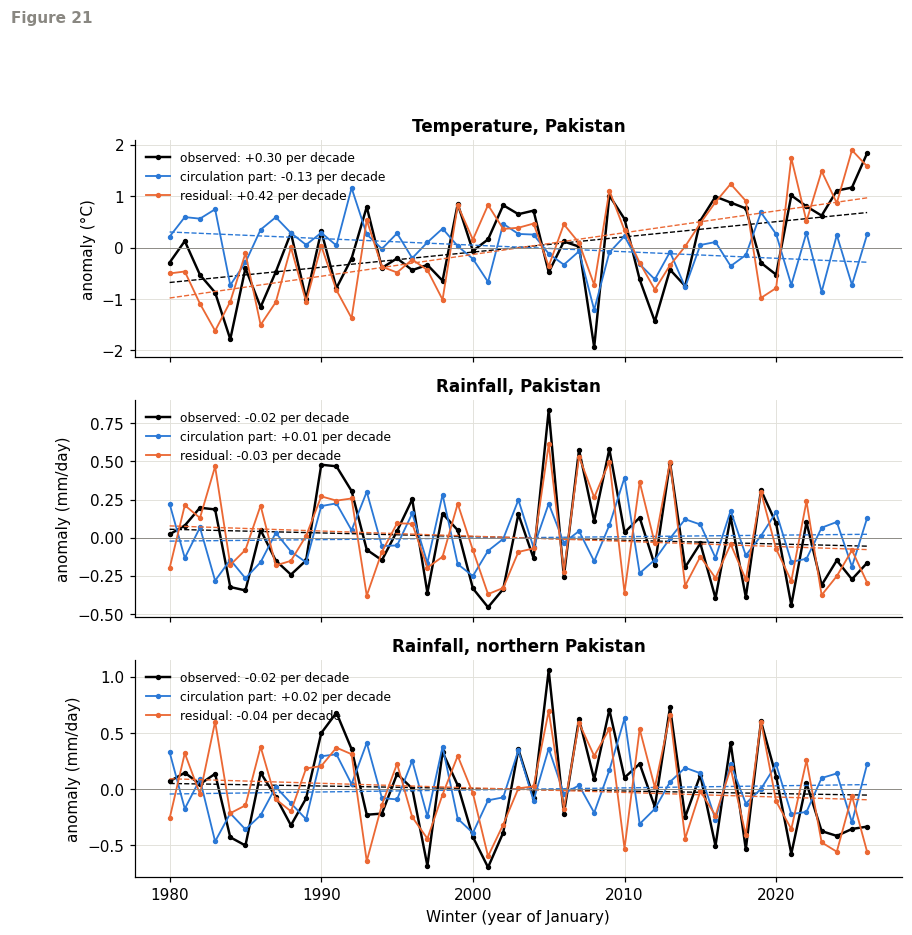

Temperature, Pakistan: observed +0.295 ± 0.182 °C per decade (p = 0.002); circulation part -0.128 ± 0.097 (p = 0.011); residual +0.423 ± 0.157 (p = 0.000). The circulation trend has the opposite sign: it has masked 30% of the residual trend. It explains 11% of the year-to-year variance of winter means, and the residual trend's standard error is 13% smaller than the observed one's.

Rainfall, Pakistan: observed -0.024 ± 0.067 mm/day per decade (p = 0.471); circulation part +0.010 ± 0.037 (p = 0.600); residual -0.034 ± 0.060 (p = 0.261). The observed trend is not significant at 10%, so no share is computed. It explains 20% of the year-to-year variance of winter means, and the residual trend's standard error is 10% smaller than the observed one's.

Rainfall, northern Pakistan: observed -0.022 ± 0.090 mm/day per decade (p = 0.618); circulation part +0.018 ± 0.055 (p = 0.508); residual -0.041 ± 0.081 (p = 0.319). The observed trend is not significant at 10%, so no share is computed. It expl

In [50]:
main = {case: dynamical_adjustment(X_MAIN, d, pls_adjust(3)) for case, d in data.items()}
decomposition = keep("dynamical_adjustment_main", decomposition_table(main))
display(decomposition.round(3))

fig, axes = plt.subplots(len(main), 1, figsize=(9, 2.9 * len(main)), sharex=True)
for ax, (case, r) in zip(axes, main.items()):
    for part, label, color, width in [("obs", "observed", "black", 1.6), ("dyn", "circulation part", BLUE, 1.2),
                                      ("res", "residual", ORANGE, 1.2)]:
        s = winter_means(r[part], r["winter"])
        x = s.index.values.astype(float)
        ax.plot(x, s.values, color=color, lw=width, marker="o", ms=2.5,
                label=f"{label}: {trend(r[part], r['winter'])['per_decade']:+.2f} per decade")
        ax.plot(x, np.polyval(np.polyfit(x, s.values, 1), x), color=color, lw=0.9, ls="--")
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set(ylabel=f"anomaly ({UNITS[case]})", title=case)
    ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Winter (year of January)")
show("21_dynamical_adjustment_timeseries")


def describe_decomposition(table: pd.DataFrame) -> None:
    """One plain sentence per target, written from the numbers so the text cannot go stale."""
    for case, row in table.iterrows():
        u = UNITS[case]
        share = row["summary", "circulation share of trend %"]
        dyn, res = row["circulation", "trend /decade"], row["residual", "trend /decade"]
        ratio = row["summary", "trend s.e., residual / observed"]
        change = f"{100 * (1 - ratio):.0f}% smaller" if ratio < 1 else f"{100 * (ratio - 1):.0f}% larger"
        print(f"{case}: observed {row['observed', 'trend /decade']:+.3f} ± {row['observed', '± 95%']:.3f} {u} per decade "
              f"(p = {row['observed', 'p']:.3f}); circulation part {row['circulation', 'trend /decade']:+.3f} "
              f"± {row['circulation', '± 95%']:.3f} (p = {row['circulation', 'p']:.3f}); residual "
              f"{row['residual', 'trend /decade']:+.3f} ± {row['residual', '± 95%']:.3f} (p = {row['residual', 'p']:.3f}). "
              + (f"The circulation trend has the opposite sign: it has masked {100 * abs(dyn) / abs(res):.0f}% of the residual trend. "
                 if np.isfinite(share) and np.sign(dyn) != np.sign(res)
                 else f"The circulation accounts for {share:.0f}% of the trend. " if np.isfinite(share)
                 else "The observed trend is not significant at 10%, so no share is computed. ")
              + f"It explains {100 * row['summary', 'circulation R², winter means (detrended)']:.0f}% of the year-to-year "
              f"variance of winter means, and the residual trend's standard error is {change} than the observed one's.\n")


describe_decomposition(decomposition)

**Result (main run, NCEP/NCAR pressure).**

- **Temperature.** Pakistan warmed by +0.30 ± 0.18 °C per decade over the winters 1980–2026 (GHCN-CAMS). The circulation part has a cooling trend of −0.13 ± 0.10 °C per decade (p = 0.01), so the residual warming is +0.42 ± 0.16 °C per decade. Sections 13.7 and 13.9 show that the residual warming is robust but the circulation cooling is not.
- **Rainfall.** There is no significant trend over Pakistan or the north (−0.02 mm/day per decade, 2–3% of the mean per decade). Neither part has a significant trend.
- **The link is weak.** The circulation part explains 11% of the year-to-year variance of temperature winter means and 19–20% for rainfall (21–24% of the monthly variance). Much of Pakistan's winter variability is not captured by sea level pressure.
- **Detection gain is modest.** Removing the circulation narrows the standard error of the trend by 10–13%.

### 13.6 What changed in the circulation?

**Figure 22** shows the trend of DJF sea level pressure in NCEP/NCAR Reanalysis 1, in hPa per decade. Dots mark p < 0.05. High ground above 1500 m is left blank. The table gives the trends of the Siberian High intensity and centre position.

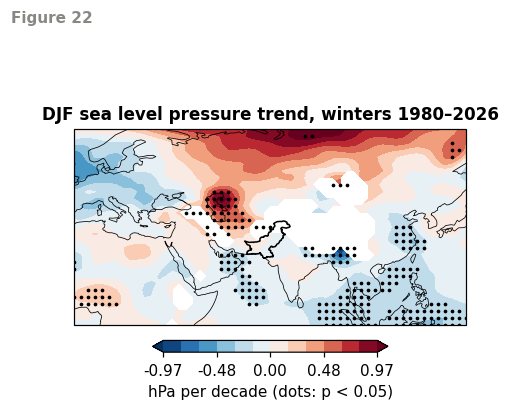

,per_decade,ci95,p
intensity (hPa),0.182,0.362,0.317
centre latitude (°N),0.222,0.535,0.402
centre longitude (°E),-0.156,0.437,0.475


In [51]:
def trend_map(field: xr.DataArray) -> tuple[np.ndarray, np.ndarray]:
    """Trend of the winter means at every grid point, per decade, and its p-value (lag-1 effective sample size)."""
    wm = field.groupby("winter").mean("time")
    x = wm.winter.values.astype(float)
    xc = x - x.mean()
    Y = wm.values - wm.values.mean(axis=0)
    slope = np.tensordot(xc, Y, axes=1) / np.sum(xc**2)
    resid = Y - slope * xc[:, None, None]
    r1 = np.clip(np.sum(resid[:-1] * resid[1:], axis=0) / np.sum(resid**2, axis=0), 0, 0.99)
    dof = np.maximum(len(x) * (1 - r1) / (1 + r1) - 2, 1)
    se = np.sqrt(np.sum(resid**2, axis=0) / dof / np.sum(xc**2))
    return 10 * slope, 2 * stats.t.sf(np.abs(slope / se), dof)


slp_trend, slp_p = trend_map(wide)                       # `wide`: DJF SLP anomalies 0-70N, 0-140E, from 12.12
height_wide = surface_height(VIEW)
if height_wide is not None:                              # grey out where SLP is extrapolated below high ground
    slp_trend = np.where(height_wide > ELEV_THRESHOLD, np.nan, slp_trend)
plot_maps([slp_trend], wide.lat.values, wide.lon.values,
          [f"DJF sea level pressure trend, winters {int(START[:4]) + 1}–{END[:4]}"], "hPa per decade (dots: p < 0.05)",
          "22_slp_trend_map", polar=False, extent=(0, 140, 0, 70), pvalues=[slp_p])

sh = siberian_high_indices()
winter_sh = data["Rainfall, Pakistan"]["winter"]
sh_trends = {name: trend(sh[:, i], winter_sh) for i, name in enumerate(["intensity (hPa)", "centre latitude (°N)", "centre longitude (°E)"])}
keep("siberian_high_trends", pd.DataFrame(sh_trends).T[["per_decade", "ci95", "p"]]).round(3)

**Result.** In NCEP/NCAR pressure, the significant rise lies just west and north-west of Pakistan, over north-east Iran, Turkmenistan and northern Afghanistan: +0.35 ± 0.33 hPa per decade averaged over 32.5–42.5°N, 52.5–67.5°E (p = 0.04, Section 13.9b). Higher pressure there drives colder northerly flow into Pakistan, which is the source of the cooling circulation part. The Siberian High shows no significant change in intensity or position (table). Section 13.9b shows that ERA5 does not reproduce this rise.

### 13.7 Result 9: does the split survive other choices?

**Figure 23** shows the circulation trend (blue) and residual trend (orange) with 95% intervals for every run, with the observed trend marked in black. The ERA5 run is added in Section 13.9.

observed  \
target                      run                                             
Temperature, Pakistan       Main: PLS-3, high ground removed        0.295   
                            PLS-3, no mask                          0.295   
                            PLS-3, ground above 1000 m removed      0.295   
                            PLS-3, ground above 2000 m removed      0.295   
                            PLS-1                                   0.295   
                            PLS-5                                   0.295   
                            Circulation analogues                   0.295   
                            Domain 0–60°N, 30–110°E                 0.295   
                            Domain 20–45°N, 50–90°E                 0.295   
                            Temperature from NCEP/NCAR              0.194   
                            Pressure from NCEP-DOE R2 (to 2025)     0.262   
Rainfall, Pakistan          Main: PLS-3, high ground removed       -0.024   
                            PLS-3, no mask                         -0.024   
                            PLS-3, ground above 1000 m removed     -0.024   
                            PLS-3, ground above 2000 m removed     -0.024   
                            PLS-1                                  -0.024   
                            PLS-5                                  -0.024   
                            Circulation analogues                  -0.024   
                            Domain 0–60°N, 30–110°E                -0.024   
                            Domain 20–45°N, 50–90°E                -0.024   
                            Pressure from NCEP-DOE R2 (to 2025)    -0.021   
Rainfall, northern Pakistan Main: PLS-3, high ground removed       -0.022   
                            PLS-3, no mask                         -0.022   
                            PLS-3, ground above 1000 m removed     -0.022   
                            PLS-3, ground above 2000 m removed     -0.022   
                            PLS-1                                  -0.022   
                            PLS-5                                  -0.022   
                            Circulation analogues                  -0.022   
                            Domain 0–60°N, 30–110°E                -0.022   
                            Domain 20–45°N, 50–90°E                -0.022   
                            Pressure from NCEP-DOE R2 (to 2025)    -0.014   

                                                                 circulation  \
target                      run                                                
Temperature, Pakistan       Main: PLS-3, high ground removed          -0.128   
                            PLS-3, no mask                            -0.063   
                            PLS-3, ground above 1000 m removed        -0.108   
                            PLS-3, ground above 2000 m removed        -0.141   
                            PLS-1                                     -0.056   
                            PLS-5                                     -0.111   
                            Circulation analogues                     -0.048   
                            Domain 0–60°N, 30–110°E                   -0.112   
                            Domain 20–45°N, 50–90°E                   -0.083   
                            Temperature from NCEP/NCAR                -0.160   
                            Pressure from NCEP-DOE R2 (to 2025)       -0.172   
Rainfall, Pakistan          Main: PLS-3, high ground removed           0.010   
                            PLS-3, no mask                            -0.010   
                            PLS-3, ground above 1000 m removed         0.018   
                            PLS-3, ground above 2000 m removed         0.010   
                            PLS-1                                     -0.010   
                            PLS-5                                      0.054   
   

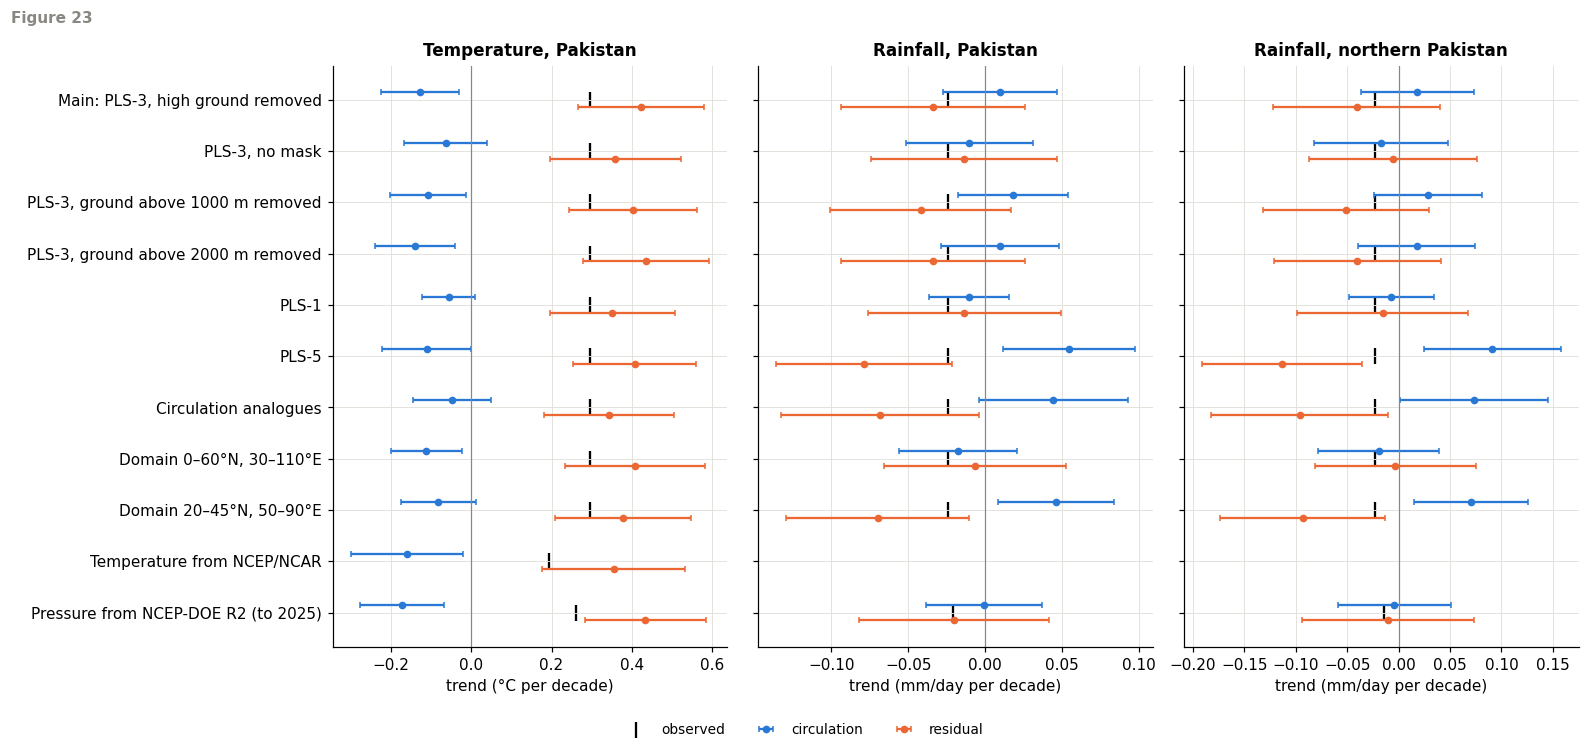

In [52]:
def masked_matrix(region: dict, start: str = START, end: str = END, name: str = "slp") -> np.ndarray:
    """pressure_matrix with high ground removed when the surface height is available."""
    X = pressure_matrix(region, start, end, name=name)
    m = low_ground(region)
    return X if m is None else X[:, m]


MAIN_LABEL = "Main: PLS-3" + (", high ground removed" if MASK is not None else "")
sensitivity_runs = {MAIN_LABEL: main}


def add_run(label: str, X: np.ndarray, method=None, cases: dict = data) -> None:
    sensitivity_runs[label] = {case: dynamical_adjustment(X, d, method or pls_adjust(3)) for case, d in cases.items()}


if MASK is not None:
    add_run("PLS-3, no mask", predictors["regional"])
    height_box = surface_height(PAKISTAN_SLP).ravel()
    for limit in (1000, 2000):
        add_run(f"PLS-3, ground above {limit} m removed", predictors["regional"][:, height_box <= limit])
add_run("PLS-1", X_MAIN, pls_adjust(1))
add_run("PLS-5", X_MAIN, pls_adjust(5))
add_run("Circulation analogues", X_MAIN, analogue_adjust())
add_run("Domain 0–60°N, 30–110°E", masked_matrix(dict(lat=(0, 60), lon=(30, 110))))
add_run("Domain 20–45°N, 50–90°E", masked_matrix(dict(lat=(20, 45), lon=(50, 90))))
add_run("Temperature from NCEP/NCAR", X_MAIN, cases={"Temperature, Pakistan": make_case("air")})

if find_file(DATASETS["slp_r2"][0]) is not None:
    r2_last = pd.Timestamp(open_field("slp_r2").time.values[-1])
    r2_end = f"{min(int(END[:4]), r2_last.year if r2_last.month >= 2 else r2_last.year - 1)}-02"
    cases_r2 = {case: make_case(name, north, START, r2_end) for case, (name, north) in CASE_SOURCES.items()}
    add_run(f"Pressure from NCEP-DOE R2 (to {r2_end[:4]})", masked_matrix(PAKISTAN_SLP, START, r2_end, "slp_r2"), cases=cases_r2)


def sensitivity_table(runs: dict) -> pd.DataFrame:
    rows = []
    for label, results in runs.items():
        table = decomposition_table(results)
        for case, row in table.iterrows():
            rows.append({"run": label, "target": case,
                         "observed": row["observed", "trend /decade"],
                         "circulation": row["circulation", "trend /decade"], "circulation ± 95%": row["circulation", "± 95%"],
                         "circulation p": row["circulation", "p"],
                         "residual": row["residual", "trend /decade"], "residual ± 95%": row["residual", "± 95%"],
                         "residual p": row["residual", "p"],
                         "circulation share %": row["summary", "circulation share of trend %"],
                         "circulation R² (winter means)": row["summary", "circulation R², winter means (detrended)"]})
    table = pd.DataFrame(rows).set_index(["target", "run"])
    order = [case for case in data if case in set(table.index.get_level_values(0))]
    return table.loc[order]


sensitivity_dyn = keep("dynamical_adjustment_sensitivity", sensitivity_table(sensitivity_runs))
display(sensitivity_dyn.round(3))


def plot_sensitivity(table: pd.DataFrame, name: str) -> None:
    """Circulation and residual trends with 95% intervals, one row per run."""
    present = set(table.index.get_level_values(0))
    targets = [case for case in data if case in present]
    fig, axes = plt.subplots(1, len(targets), figsize=(4.8 * len(targets), 0.42 * len(sensitivity_runs) + 1.6), sharey=True)
    labels = list(sensitivity_runs)
    for ax, case in zip(np.atleast_1d(axes), targets):
        sub = table.loc[case]
        for part, color, dy in [("circulation", BLUE, -0.15), ("residual", ORANGE, 0.15)]:
            ys = [labels.index(run) + dy for run in sub.index]
            ax.errorbar(sub[part], ys, xerr=sub[f"{part} ± 95%"], fmt="o", color=color, ms=4, capsize=2, label=part)
        ax.scatter(sub["observed"], [labels.index(run) for run in sub.index], marker="|", s=120, color="black", label="observed")
        ax.axvline(0, color=GREY, lw=0.8)
        ax.set(title=case, xlabel=f"trend ({UNITS[case]} per decade)")
    ax0 = np.atleast_1d(axes)[0]
    ax0.set_yticks(range(len(labels)), labels)
    ax0.invert_yaxis()
    handles, names = ax0.get_legend_handles_labels()
    fig.tight_layout()
    fig.legend(handles, names, loc="upper center", bbox_to_anchor=(0.5, 0), ncol=3, fontsize=9)
    show(name)


plot_sensitivity(sensitivity_dyn, "23_dynamical_adjustment_sensitivity")

**Result (all 12 runs, including ERA5 from Section 13.9).**

- **Temperature: the residual warming is robust.** It is +0.32 to +0.44 °C per decade in all 12 runs (all p < 0.001), and never smaller than the observed trend.
- **Temperature: the circulation cooling is not robust.** It is negative in all 12 runs, but its size depends on the reanalysis. In the 11 NCEP-based runs it is −0.05 to −0.17 °C per decade and significant in 7 (the main run, the 1000 m and 2000 m cut-offs, 5 modes, the wider domain, NCEP/NCAR temperature and NCEP-DOE R2 pressure). With ERA5 pressure it is −0.02 ± 0.09 (p = 0.63).
- **Removing high ground matters** in NCEP: without the mask the cooling halves (−0.06 against −0.13).
- **Rainfall: no robust result.** The residual trend is significant in only 3 of 11 runs, and both parts change sign between runs. There is no observed rainfall trend for the split to explain.

### 13.8 Result 10: what made the extreme winters?

**Figure 24** splits the three warmest and three coldest winters, and the three wettest and three driest winters in northern Pakistan, into their circulation part (blue) and residual (orange). The black dot is the observed anomaly. A winter whose anomaly is mostly orange was made unusual by the background change, not by the weather pattern.

observed  circulation  residual     kind  \
target                      winter                                             
Temperature, Pakistan       2026        1.83         0.26      1.58  highest   
                            2025        1.17        -0.73      1.89  highest   
                            2024        1.11         0.24      0.86  highest   
                            2008       -1.94        -1.21     -0.72   lowest   
                            1984       -1.78        -0.73     -1.05   lowest   
                            2012       -1.44        -0.62     -0.82   lowest   
Rainfall, northern Pakistan 2005        1.06         0.36      0.70  highest   
                            2013        0.73         0.07      0.66  highest   
                            2009        0.71         0.17      0.54  highest   
                            2001       -0.69        -0.10     -0.60   lowest   
                            1997       -0.68        -0.24     -0.44   lowest   
                            2021       -0.57        -0.22     -0.35   lowest   

                                    circulation share %  
target                      winter                       
Temperature, Pakistan       2026                  13.93  
                            2025                 -62.32  
                            2024                  21.84  
                            2008                  62.56  
                            1984                  40.98  
                            2012                  43.11  
Rainfall, northern Pakistan 2005                  34.26  
                            2013                   9.01  
                            2009                  23.91  
                            2001                  14.15  
                            1997                  35.51  
                            2021                  38.31

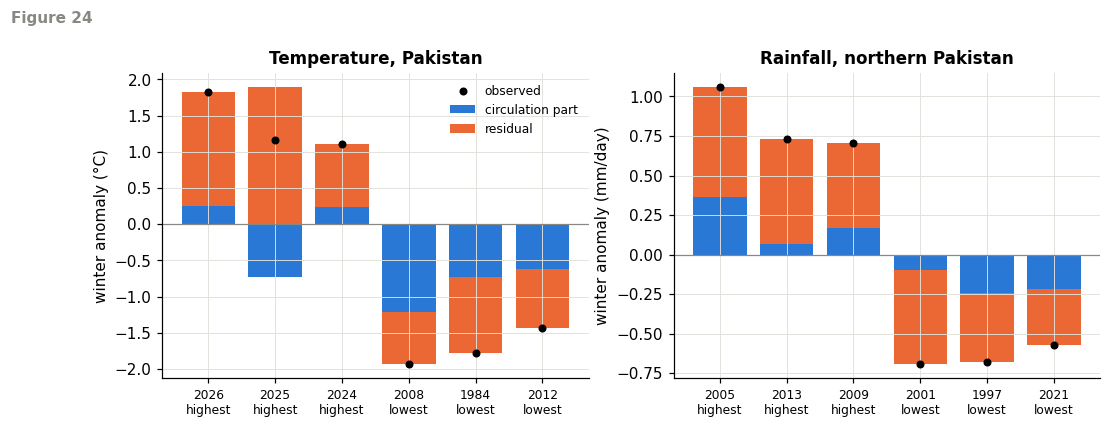

In [53]:
def extreme_winters(r: dict, n: int = 3) -> pd.DataFrame:
    """The n highest and n lowest winters, each split into circulation part and residual."""
    w = pd.DataFrame({part: winter_means(r[part], r["winter"]) for part in ("obs", "dyn", "res")})
    picks = pd.concat([w.nlargest(n, "obs").assign(kind="highest"), w.nsmallest(n, "obs").assign(kind="lowest")])
    picks["circulation share %"] = 100 * picks["dyn"] / picks["obs"]
    return picks.rename(columns={"obs": "observed", "dyn": "circulation", "res": "residual"})


extremes = pd.concat({case: extreme_winters(main[case]) for case in ["Temperature, Pakistan", "Rainfall, northern Pakistan"]},
                     names=["target", "winter"])
display(keep("extreme_winters_decomposed", extremes).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, case in zip(axes, ["Temperature, Pakistan", "Rainfall, northern Pakistan"]):
    sub = extremes.loc[case]
    x = np.arange(len(sub))
    ax.bar(x, sub["circulation"], color=BLUE, label="circulation part")
    ax.bar(x, sub["residual"], bottom=np.where(np.sign(sub["residual"]) == np.sign(sub["circulation"]), sub["circulation"], 0),
           color=ORANGE, label="residual")
    ax.scatter(x, sub["observed"], color="black", zorder=3, s=18, label="observed")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xticks(x, [f"{w}\n{k}" for w, k in zip(sub.index, sub["kind"])], fontsize=8)
    ax.set(title=case, ylabel=f"winter anomaly ({UNITS[case]})")
axes[0].legend(fontsize=8)
show("24_extreme_winters")

**Result (main run).** The three warmest winters on record are the last three, 2024–2026, and all three were warm mainly through the residual. In 2025 the circulation pointed to a winter 0.7 °C colder than normal, yet it was 1.2 °C warmer. The coldest winters (2008, 1984, 2012) owed more to the circulation, 41–63% of their anomaly. For northern rainfall, the residual dominates both the wettest and the driest winters, and the circulation part explains 9–38% of each.

### 13.9 ERA5

The split repeated with ERA5 sea level pressure (Copernicus Climate Change Service), the current standard reanalysis. DJF monthly means for 1979–2026 over 0–70°N, 0–140°E are retrieved from the Climate Data Store on the 2.5° NCEP grid, so the high-ground mask is identical.

In [54]:
import sys
import subprocess

ERA5_FILE = DATA_DIR / "era5_msl_djf.nc"
ERA5_AREA = [70, 0, 0, 140]                 # north, west, south, east: the Pakistan box and the trend map
CDS_TOKEN = ""                              # Copernicus token; if empty, read from the Colab secret CDS_TOKEN


def cds_token() -> str | None:
    """The token from CDS_TOKEN, else from the Colab secret of that name."""
    if CDS_TOKEN.strip():
        return CDS_TOKEN.strip()
    try:
        from google.colab import userdata
        return userdata.get("CDS_TOKEN").strip()
    except Exception:
        return None


def era5_covers_map(path: Path) -> bool:
    """True if an existing ERA5 file spans the whole map area (an earlier, smaller download does not)."""
    try:
        ds = xr.open_dataset(path)
        lat = ds["latitude" if "latitude" in ds.coords else "lat"].values
        lon = ds["longitude" if "longitude" in ds.coords else "lon"].values % 360
        return lat.max() >= ERA5_AREA[0] - 0.1 and lat.min() <= ERA5_AREA[2] + 0.1 and lon.max() >= ERA5_AREA[3] - 0.1
    except Exception:
        return False


if ERA5_FILE.exists() and era5_covers_map(ERA5_FILE):
    print(f"{ERA5_FILE} already present.")
elif (token := cds_token()) is None:
    print("No Copernicus token found: set the Colab secret CDS_TOKEN or fill in CDS_TOKEN above. ERA5 is skipped.")
    NOTES.append("ERA5 not downloaded: no Copernicus token")
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cdsapi"], check=True)
    Path.home().joinpath(".cdsapirc").write_text(f"url: https://cds.climate.copernicus.eu/api\nkey: {token}\n")
    import cdsapi
    try:
        cdsapi.Client().retrieve("reanalysis-era5-single-levels-monthly-means", {
            "product_type": ["monthly_averaged_reanalysis"],
            "variable": ["mean_sea_level_pressure"],
            "year": [str(y) for y in range(1979, int(END[:4]) + 1)],
            "month": ["01", "02", "12"],
            "time": ["00:00"],
            "area": ERA5_AREA,
            "grid": [2.5, 2.5],
            "data_format": "netcdf",
            "download_format": "unarchived",
        }, str(ERA5_FILE))
        print(f"saved {ERA5_FILE} ({ERA5_FILE.stat().st_size / 1e6:.1f} MB)")
    except Exception as error:                                     # most often: licence not accepted, or a wrong token
        ERA5_FILE.unlink(missing_ok=True)
        NOTES.append(f"ERA5 download failed: {error}")
        print("ERA5 download failed:", error)
        print("Check that the token is right and that the ERA5 Terms of Use are accepted on the dataset page.")

2026-11-10 20:54:01,152 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-10 20:54:01,658 INFO Request ID is 6f5a3350-d0d1-4f7d-b0df-4a0996b87879
INFO:ecmwf.datastores.legacy_client:Request ID is 6f5a3350-d0d1-4f7d-b0df-4a0996b87879
2026-11-10 20:54:01,804 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2

9501fbcb786788eb2014d8b315e85861.nc:   0%|          | 0.00/458k [00:00<?, ?B/s]

saved data/era5_msl_djf.nc (0.5 MB)


,observed,circulation,circulation ± 95%,circulation p,residual,residual ± 95%,residual p,circulation share %,circulation R² (winter means)
target,,,,,,,,,
"Temperature, Pakistan",0.295,-0.022,0.093,0.634,0.318,0.151,0.000,-7.485,0.135
"Rainfall, Pakistan",-0.024,-0.032,0.036,0.081,0.008,0.060,0.793,NaN,0.174
"Rainfall, northern Pakistan",-0.022,-0.044,0.052,0.095,0.022,0.085,0.611,NaN,0.105


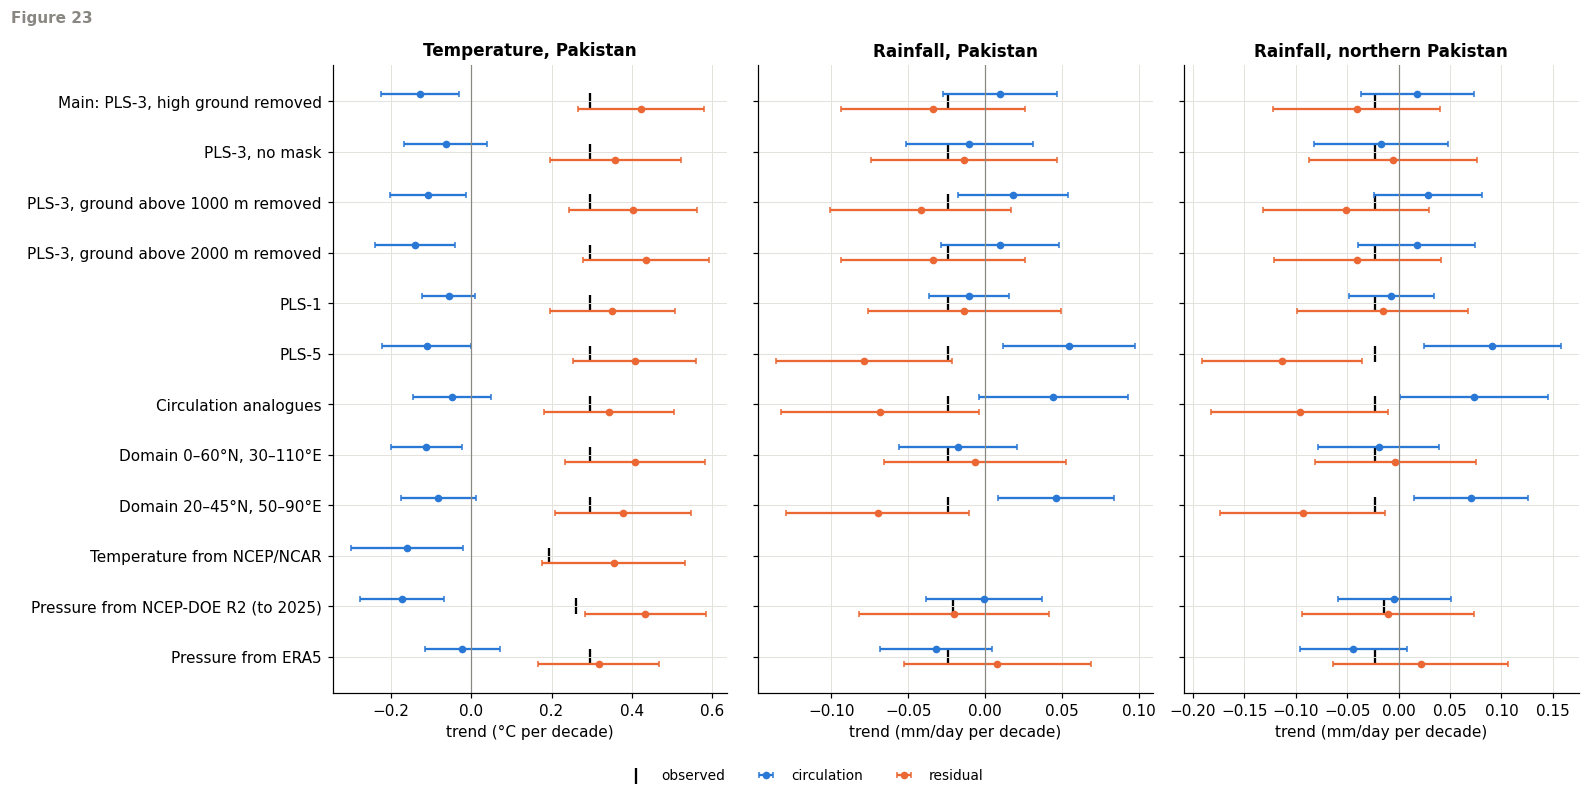

ERA5 has a circulation cooling of the same sign but not significant: circulation -0.022 ± 0.093 °C per decade (p = 0.634), residual +0.318 ± 0.151 (p = 0.000).


In [55]:
def open_era5() -> xr.DataArray | None:
    """ERA5 mean sea level pressure (hPa) as (time, lat, lon), latitude ascending, longitude 0-360."""
    if not ERA5_FILE.exists():
        return None
    da = xr.open_dataset(ERA5_FILE)["msl"]
    da = da.rename({k: v for k, v in {"valid_time": "time", "latitude": "lat", "longitude": "lon"}.items() if k in da.dims})
    if "expver" in da.dims:                                         # older CDS files split final and preliminary data
        da = da.mean("expver", skipna=True)
    if "number" in da.dims:
        da = da.isel(number=0)
    da = da.drop_vars([c for c in ("expver", "number") if c in da.coords])
    da = da.assign_coords(lon=da.lon % 360).sortby("lon").sortby("lat") / 100
    return da.assign_attrs(units="hPa")


def on_grid(da: xr.DataArray, grid: xr.DataArray) -> xr.DataArray:
    """Pick the points of `da` that match the lat/lon of `grid` (both 2.5°)."""
    lat, lon = grid.lat.values, grid.lon.values
    return da.sel(lat=lat, lon=lon, method="nearest").assign_coords(lat=lat, lon=lon)


def era5_matrix(start: str = START, end: str = END) -> np.ndarray | None:
    """ERA5 pressure over the Pakistan box, area-weighted, high ground removed, as (n, p)."""
    era = open_era5()
    if era is None:
        return None
    field = select_winters(on_grid(era, select_box(slp, **PAKISTAN_SLP)), start, end)
    if field.sizes["time"] != len(MONTH):
        NOTES.append(f"ERA5 file covers {field.sizes['time']} of {len(MONTH)} DJF months: not used")
        print(f"ERA5 covers {field.sizes['time']} of {len(MONTH)} DJF months: not used.")
        return None
    X = (field.values * area_weights(field)).reshape(field.sizes["time"], -1)
    return X if MASK is None else X[:, MASK]


X_era5 = era5_matrix()
if X_era5 is None:
    print("ERA5 not available: run skipped.")
else:
    add_run("Pressure from ERA5", X_era5)
    sensitivity_dyn = keep("dynamical_adjustment_sensitivity", sensitivity_table(sensitivity_runs))
    era5_rows = sensitivity_dyn.xs("Pressure from ERA5", level="run")
    display(era5_rows.round(3))
    plot_sensitivity(sensitivity_dyn, "23_dynamical_adjustment_sensitivity")
    t = era5_rows.loc["Temperature, Pakistan"]
    verdict = ("confirms the circulation cooling" if t["circulation"] < 0 and t["circulation p"] < 0.05
               else "has a circulation cooling of the same sign but not significant" if t["circulation"] < 0
               else "does NOT show the circulation cooling")
    print(f"ERA5 {verdict}: circulation {t['circulation']:+.3f} ± {t['circulation ± 95%']:.3f} °C per decade "
          f"(p = {t['circulation p']:.3f}), residual {t['residual']:+.3f} ± {t['residual ± 95%']:.3f} (p = {t['residual p']:.3f}).")

**Result.** With ERA5 pressure the residual warming is +0.32 ± 0.15 °C per decade (p < 0.001), but the circulation part is only −0.02 ± 0.09 °C per decade (p = 0.63). The circulation cooling found with NCEP pressure is not confirmed.

### 13.9b The pressure trend in NCEP and in ERA5

**Figure 25** draws the trend map from both reanalyses, with high ground left blank and significant points dotted. The table compares the trend averaged over 32.5–42.5°N, 52.5–67.5°E (north-east Iran, Turkmenistan, northern Afghanistan).

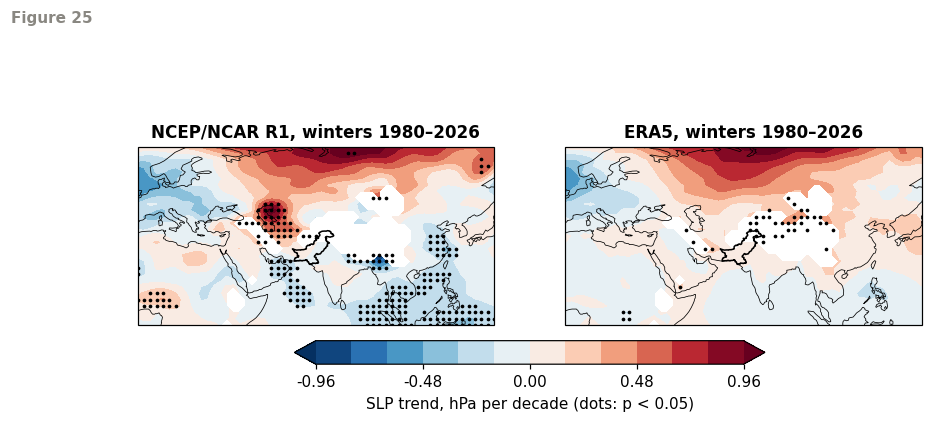

,"trend west of Pakistan, hPa/decade",± 95%,p
NCEP/NCAR R1,0.346,0.334,0.043
ERA5,0.121,0.335,0.472


Pattern correlation of the two trend maps over low ground: r = 0.86
ERA5 shows a pressure rise of the same sign west of Pakistan, but it is not significant.

In [56]:
WEST_BOX = dict(lat=(32.5, 42.5), lon=(52.5, 67.5))       # north-east Iran, Turkmenistan, northern Afghanistan

era = open_era5()
if era is None or not era5_covers_map(ERA5_FILE):
    print("ERA5 covering 0-70°N, 0-140°E not available: map skipped.")
else:
    era_wide = anomalies(select_winters(on_grid(era, wide.isel(time=0)), START, END))
    era_trend, era_p = trend_map(era_wide)
    if height_wide is not None:
        era_trend = np.where(height_wide > ELEV_THRESHOLD, np.nan, era_trend)
    years = f"winters {int(START[:4]) + 1}–{END[:4]}"
    plot_maps([slp_trend, era_trend], wide.lat.values, wide.lon.values,
              [f"NCEP/NCAR R1, {years}", f"ERA5, {years}"], "SLP trend, hPa per decade (dots: p < 0.05)",
              "25_slp_trend_ncep_vs_era5", polar=False, extent=(0, 140, 0, 70), pvalues=[slp_p, era_p])

    low = np.isfinite(slp_trend) & np.isfinite(era_trend)
    pattern_r = np.corrcoef(slp_trend[low], era_trend[low])[0, 1]
    frac = box_fraction(wide.lat.values, wide.lon.values, WEST_BOX)
    if height_wide is not None:
        frac = frac * (height_wide <= ELEV_THRESHOLD)
    rows = {}
    for name, field in [("NCEP/NCAR R1", wide), ("ERA5", era_wide)]:
        st = trend(region_mean(field, frac).values, field.winter.values)
        rows[name] = {"trend west of Pakistan, hPa/decade": st["per_decade"], "± 95%": st["ci95"], "p": st["p"]}
    table = keep("slp_trend_ncep_vs_era5", pd.DataFrame(rows).T)
    display(table.round(3))
    print(f"Pattern correlation of the two trend maps over low ground: r = {pattern_r:.2f}")
    e = table.loc["ERA5"]
    print("ERA5 " + ("confirms the pressure rise west of Pakistan." if e.iloc[0] > 0 and e["p"] < 0.05
                     else "shows a pressure rise of the same sign west of Pakistan, but it is not significant." if e.iloc[0] > 0
                     else "does NOT confirm the pressure rise west of Pakistan."))

**Result.** The large-scale patterns agree (pattern correlation 0.86 over low ground): pressure rose over the Arctic coast and Siberia in both. The rise west of Pakistan does not. It is +0.35 ± 0.33 hPa per decade in NCEP (p = 0.04) but +0.12 ± 0.34 in ERA5 (p = 0.47), and the significant NCEP centre over Turkmenistan and north-east Iran is absent from ERA5. NCEP also shows significant falls over the Arabian Sea and the Bay of Bengal that ERA5 does not. The circulation cooling of the NCEP runs therefore most likely comes from regional pressure trends specific to the NCEP reanalyses.

### 13.10 What this section can claim, and its limits

**What a paper can claim.**

1. **Pakistan's winter warming is not circulation-driven.** After removing the circulation, the residual warming is +0.32 to +0.44 °C per decade in all 12 configurations, ERA5 included (p < 0.001), and never smaller than the observed +0.30 °C per decade. Circulation change has not contributed to the warming.
2. **The circulation contribution depends on the reanalysis.** NCEP-based runs suggest the circulation offset part of the warming (−0.05 to −0.17 °C per decade, significant in 7 of 11 runs), through a pressure rise west of Pakistan. ERA5 shows neither (−0.02 °C per decade, p = 0.63). Dynamical adjustment over this region should not rely on NCEP pressure alone.
3. **Recent record warmth is residual warming.** The three warmest winters, 2024–2026, were warm mainly through the residual, one of them against a cold circulation.
4. **Rainfall.** Winter rainfall has no trend since 1980, and the split finds no robust circulation or residual trend in it.
5. **Method.** The decomposition is cross-validated and checked on synthetic targets. At the link strength of the real data it recovers the residual trend, but cannot resolve circulation trends of about 0.1 °C per decade.

**Limits.**

- **Weak link.** Sea level pressure explains only 11–29% of the year-to-year variance of Pakistan's winter temperature, so the circulation part of the trend is uncertain.
- **The residual is not purely thermodynamic.** It also holds circulation that sea level pressure misses (for example upper-level jet changes, which Hunt 2024 links to more frequent January western disturbances), land-surface effects and aerosols. It is reported as "residual", not "forced".
- **Main run on NCEP pressure.** The main run and most sensitivity runs use NCEP pressure, which Section 13.9b shows to be less reliable here than ERA5. The robust result, the residual warming, holds in both.
- **A stable link is assumed.** Learning from detrended data assumes the circulation–target link does not change over time. The split-sample test of Section 12.8 supports this for 1980–2026.
- **Rainfall data.** The rainfall split rests on GPCP, the only dataset that passed Section 12.9.

## 14. Summary

**Replication (Sections 4–8).** On the paper's own sample, EOF1 and EOF2 explain 21.6% and 13.2% of the variance against the quoted 21% and 13%. PC1 correlates with NOAA's AO index at |r| = 0.98. The numbers require √cos φ weighting of the data. All ten numerical checks of the Section 3 properties pass.

**Application (Section 9).** The AO does not explain Pakistan's winters. On a Pakistan-centred domain for 1997–2026, EOF1 (a push of the Siberian High) goes with colder months and EOF2 with drier months, each explaining about 15% of the variance in the same month. Over 1980–2026 the rainfall link moves to EOF4 (Section 12.5).

**Robustness (Section 11).** Counting independent months widens the paper's error bars by about half. EOF1 stays a clear mode. EOF2 overlaps EOF3 and its map is unstable under resampling.

**Research gap (Section 12).** Ranking patterns by pressure variance hides the circulation that matters for Pakistan. Out of sample, the AO, Siberian High indices and the three leading regional EOFs explain 0–3% of monthly winter rainfall. Three target-oriented modes explain 25–32% of rainfall and temperature, across 81 domains, both halves of 1980–2026 and two reanalyses. Ten EOFs reach the same rainfall skill, so the gain is compactness and stability. The patterns are a weak Siberian High for warm months and a western-disturbance trough for wet months. They describe the same month and give no one-month forecast, and neither does Niño 3.4.

**Circulation and residual trends (Section 13).** A cross-validated dynamical adjustment splits Pakistan's 1980–2026 winter trends into a circulation part and a residual. It is checked on synthetic targets and run in 12 configurations: two methods, three elevation cut-offs, three domains, three numbers of modes, two temperature datasets and three reanalyses. The residual warming is +0.32 to +0.44 °C per decade in every configuration, never smaller than the observed +0.30, so Pakistan's winter warming is not circulation-driven. NCEP pressure suggests the circulation offset part of it, through a pressure rise west of Pakistan, but ERA5 does not confirm this (−0.02 °C per decade, p = 0.63). The three warmest winters, 2024–2026, were warm mainly through the residual. Winter rainfall has no trend and no robust split.

## 15. Outputs

Every table is written to `review/tables/`, a summary of the run to `review/summary.json`, and the folder with the figures is zipped to `review_bundle.zip`.

In [57]:
import json
import platform
import shutil

inventory = {}
for name, (file, var, units) in DATASETS.items():
    path = DATA_DIR / file if (DATA_DIR / file).exists() else DATA_DIR / "compact" / file
    if path.exists():
        field = open_field(name)
        inventory[name] = dict(file=str(path), first=str(field.time.values[0])[:7], last=str(field.time.values[-1])[:7],
                               grid=f"{field.sizes['lat']} x {field.sizes['lon']}")
    else:
        inventory[name] = dict(file=str(path), found=False)
inventory["nino34"] = dict(file=str(DATA_DIR / "nina34.anom.data"), found=load_nino34() is not None)

summary = {
    "created": pd.Timestamp.now().isoformat(timespec="seconds"),
    "versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "xarray": xr.__version__},
    "periods": {"run_a": PAPER_PERIOD, "run_b": LAST_30, "section_12": (START, END)},
    "data": inventory,
    "replication": {"run_a_eof1_pct": paper.var_pct[0], "run_a_eof2_pct": paper.var_pct[1],
                    "run_b_eof1_pct": recent.var_pct[0], "run_b_eof2_pct": recent.var_pct[1],
                    "checks_passed": f"{sum(checks.values())} of {len(checks)}"},
    "tables": sorted(TABLES),
    "figures": sorted(p.name for p in (REVIEW / "figures").glob("*.png")),
    "notes": NOTES,
}
for name, table in TABLES.items():
    table.to_csv(REVIEW / "tables" / f"{name}.csv")
(REVIEW / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
shutil.make_archive("review_bundle", "zip", REVIEW)

print(f"Wrote {len(TABLES)} tables and {len(summary['figures'])} figures to review/ and review_bundle.zip")
for note in NOTES:
    print("Note:", note)

Wrote 30 tables and 25 figures to review/ and review_bundle.zip


## 16. Next steps

1. **Make ERA5 the main pressure dataset.** Section 13.9 shows that ERA5 is more reliable than NCEP over this region. Rerun Sections 12–13 with ERA5 as the main predictor and keep the NCEP runs as sensitivity tests.
2. **Add upper-level circulation.** Use ERA5 500 hPa geopotential height and 200 hPa wind as predictors. Hunt (2024) links more frequent January western disturbances to a stronger subtropical jet, which sea level pressure does not capture. This tests whether part of the residual is circulation after all.
3. **Compare the residual with the forced response.** Check whether the residual warming of +0.32 to +0.44 °C per decade matches the forced warming in large climate-model ensembles (as Deser and Phillips 2023 do for Europe). A match would support reading the residual as forced warming.
4. **Use station data.** Temperature and rainfall records from the Pakistan Meteorological Department would settle the disagreement between GPCP and PREC/L (Section 12.9) and remove the remaining dependence on gridded products.
5. **Test seasonal prediction.** Use seasonal means and autumn sea surface temperature (ENSO, Indian Ocean Dipole) as predictors, with the same leave-one-winter-out cross-validation.
6. **Look at extremes.** Repeat the split for cold waves, fog and snowfall with daily data and circulation analogues.
7. **Write the manuscript.** Suggested structure: replication (Sections 4–8, 11) → which patterns matter out of sample (Section 12) → the warming is not circulation-driven (Section 13) → the NCEP and ERA5 difference as a caution for regional dynamical adjustment. Suitable journals: *International Journal of Climatology*, *Theoretical and Applied Climatology*.

## References

All literature cited is from 2022 or later, except the method sources listed separately.

### Literature (2022 onward)

- Abbas, A., et al. (2023). Characteristics of winter precipitation over Pakistan and possible causes during 1981–2018. *Water*, 15, 2420.
- Abbas, H., Song, W., Wang, Y., Xiang, K., Chen, L., Feng, T., Linghu, S., and Alam, M. (2024). Validation of CRU TS v4.08, ERA5-Land, IMERG v07B, and MSWEP v2.8 precipitation estimates against observed values over Pakistan. *Remote Sensing*, 16, 4803. https://doi.org/10.3390/rs16244803
- Deser, C., and Phillips, A. S. (2023). A range of outcomes: the combined effects of internal variability and anthropogenic forcing on regional climate trends over Europe. *Nonlinear Processes in Geophysics*, 30, 63–84. https://doi.org/10.5194/npg-30-63-2023
- Hunt, K. M. R. (2024). Increasing frequency and lengthening season of western disturbances are linked to increasing strength and delayed northward migration of the subtropical jet. *Weather and Climate Dynamics*, 5, 345–356. https://doi.org/10.5194/wcd-5-345-2024
- Hunt, K. M. R., Baudouin, J.-P., Turner, A. G., Dimri, A. P., Jeelani, G., Pooja, Chattopadhyay, R., Cannon, F., Arulalan, T., Shekhar, M. S., Sabin, T. P., and Palazzi, E. (2025). Western disturbances and climate variability: a review of recent developments. *Weather and Climate Dynamics*, 6, 43–112. https://doi.org/10.5194/wcd-6-43-2025
- Karim, R., et al. (2023). Winter surface air temperature variation over Pakistan during 1970–2014 and its principal drivers in the tropical ocean. *Journal of Atmospheric and Solar-Terrestrial Physics*, 242, 105996.
- Lan, C., He, Y., Wang, Z., Huo, Z., Ni, B., and Guan, X. (2026). Dynamical and thermodynamic drivers of the divergent trends in Northern Hemisphere winter extreme cold events. *Climate Dynamics*, 64, 493. https://doi.org/10.1007/s00382-026-08460-1
- Li, D., Zhou, T., Qi, Y., Zou, L., Li, C., Zhang, W., and Chen, X. (2024). Future reduction of cold extremes over East Asia due to thermodynamic and dynamic warming. *Atmospheric Chemistry and Physics*, 24, 7347–7358. https://doi.org/10.5194/acp-24-7347-2024
- Najeeb, R., Rashid, I. U., Ahmed, R., Abid, M. A., Ghasemifar, E., and Alsafari, I. (2026). Early winter precipitation variability over Pakistan and associated ENSO teleconnections. *Theoretical and Applied Climatology*, 157, 488. https://doi.org/10.1007/s00704-026-06406-5
- Pfleiderer, P., Merrifield, A., Dunkl, I., Durand, H., Cariou, E., Cattiaux, J., Camps-Valls, G., and Sippel, S. (2026). Considerable yet contrasting regional imprint of circulation change on summer temperature trends across the Northern Hemisphere mid-latitudes. *Weather and Climate Dynamics*, 7, 89–108. https://doi.org/10.5194/wcd-7-89-2026
- Rebi, A., et al. (2023). Spatiotemporal precipitation trends and associated large-scale teleconnections in northern Pakistan. *Atmosphere*, 14, 871.
- Shields, C. A., DeSantis, D., Jonko, A., Lee, J., Caron, J. M., Phillips, A. S., et al. (2026). Challenges and alternatives to empirical orthogonal functions for earth system data. *Scientific Reports*, 16, 18794. https://doi.org/10.1038/s41598-026-49505-z
- Vautard, R., et al. (2023). Heat extremes in Western Europe increasing faster than simulated due to atmospheric circulation trends. *Nature Communications*, 14, 6803. https://doi.org/10.1038/s41467-023-42143-3

### Data sources

- Copernicus Climate Change Service (C3S) (2019). *ERA5 monthly averaged data on single levels from 1940 to present*. Climate Data Store. https://doi.org/10.24381/cds.f17050d7. Used under the CC BY 4.0 licence; regridded to 2.5° and converted to seasonal anomalies.
- NOAA Physical Sciences Laboratory: NCEP/NCAR Reanalysis 1, NCEP-DOE Reanalysis 2, GPCP v2.3, GHCN-CAMS and PREC/L monthly means, and the Niño 3.4 index. https://psl.noaa.gov
- NOAA Climate Prediction Center: monthly Arctic Oscillation index. https://www.cpc.ncep.noaa.gov

### Method sources

These define the formulas the code uses. The first is the paper this notebook replicates. Journals expect the originals of formulas to be cited.

- Hannachi, A. (2004). *A primer for EOF analysis of climate data*. University of Reading.
- North, G. R., et al. (1982). Sampling errors in the estimation of empirical orthogonal functions. *Monthly Weather Review*, 110, 699–706. (The paper's equation 12.)
- Bretherton, C. S., et al. (1999). The effective number of spatial degrees of freedom of a time-varying field. *Journal of Climate*, 12, 1990–2009. (Effective sample size of correlations.)
- Santer, B. D., et al. (2000). Statistical significance of trends and trend differences in layer-average atmospheric temperature time series. *Journal of Geophysical Research*, 105, 7337–7356. (Effective sample size of trends.)